# Лекция 11. Визуальные токенизаторы и авторегрессионная генерация

Курс «Современное компьютерное зрение». Блокнот рассчитан на запуск в Google Colab (бесплатный GPU T4) и проверен на CPU в режиме `FAST_DEV_RUN`. Все ячейки уже выполнены, результаты сохранены: блокнот можно читать как учебник, не запуская. На GPU блокнот в сохранённом виде не запускался: путь с полным числом шагов обучения исполнением не проверен.

В лекциях 5–9 изображение было входом: CLIP и SigLIP превращали его в вектор, VLM — в последовательность визуальных токенов, которые языковая модель читает вместе с текстом. В лекции 10 мы уже пользовались генератором изображений, но как готовым инструментом. Теперь посмотрим в обратную сторону: как модель сама порождает изображение. Центральная идея лекции — изображение можно превратить в короткую последовательность дискретных символов (визуальных токенов), а затем генерировать эти символы той же машиной, что генерирует текст: трансформером, предсказывающим следующий токен. Для этого нужны две вещи: визуальный токенизатор (VQ-VAE, VQGAN и их потомки), который сжимает изображение в токены и умеет восстанавливать его обратно, и авторегрессионный приор, который учится распределению этих токенов.

## Цели лекции

После лекции вы сможете:

1. Сформулировать задачу генеративного моделирования через правдоподобие, перевести правдоподобие в bits/dim и объяснить, чем явные модели плотности отличаются от неявных.
2. Вывести ELBO для модели с латентными переменными и объяснить, откуда берутся размытость VAE и posterior collapse.
3. Описать генеративную трилемму (качество, покрытие мод, скорость) и место в ней VAE, GAN, диффузии и авторегрессионных моделей.
4. Записать потерю VQ-VAE (реконструкция, codebook loss, commitment loss), объяснить straight-through estimator и механизм коллапса кодов, перечислить способы лечения (инициализация данными, перезапуск мёртвых кодов, низкоразмерные нормированные коды, FSQ, LFQ).
5. Объяснить, что VQGAN добавляет к VQ-VAE (перцептивная и adversarial-потери, адаптивный вес) и зачем.
6. Рассчитать длину последовательности и число бит на изображение для заданных разрешения, степени сжатия $f$ и размера codebook; сравнить токенизаторы современных генераторов и VLM.
7. Сравнить авторегрессионные приоры: ImageGPT по пикселям, трансформер по кодам VQ, MaskGIT и VAR с предсказанием следующего масштаба.
8. Управлять сэмплингом через temperature, top-k и top-p и объяснить компромисс качество–разнообразие.

## Как устроен блокнот

Часть I «Теория» (разделы 1–12) — правдоподобие и латентные переменные, трилемма, VAE, VQ-VAE и коллапс кодов, VQGAN, длина последовательности, токенизаторы в современных моделях, авторегрессионные приоры, сэмплинг и оценка. Часть II «Практикум» (разделы 13–24) — всё то же своими руками на MNIST: VAE, три варианта VQ-VAE, токенизаторы с $f = 2, 4, 8$, VQGAN-lite, предобученный TAESD на реальной фотографии, пиксельный авторегрессор в духе ImageGPT, трансформер по кодам, перебор temperature, top-k и top-p, мини-VAR и сводная таблица. В конце — выводы, контрольные вопросы, задания и источники.

Режим запуска задаёт переменная `FAST_DEV_RUN` в ячейке настройки: на CPU она включается автоматически и сокращает число шагов обучения. Числа в тексте практикума взяты из сохранённого CPU-прогона. На GPU они будут другими: переносить стоит процедуру и направление эффектов, а не значения.

## Обозначения

| Символ | Смысл |
|---|---|
| $x$ | изображение; $x_i$ — его $i$-й символ (пиксель или токен) |
| $p_{\text{data}}(x)$, $p_\theta(x)$ | распределение данных и модели с параметрами $\theta$ |
| $z$ | латентная переменная; $z_e$ — выход энкодера, $z_q$ — квантованный вектор |
| $q_\phi(z \mid x)$ | приближённое апостериорное распределение (энкодер) |
| $\mathcal{C} = \{e_1, \dots, e_K\}$ | codebook из $K$ векторов размерности $D$ |
| $\mathrm{sg}[\cdot]$ | stop-gradient: значение без изменений, градиент 0 |
| $f$ | степень пространственного сжатия: один токен на $f \times f$ пикселей |
| $N$ | длина последовательности токенов, $N = \frac{H}{f} \cdot \frac{W}{f}$ |
| $T$, $k$, $p$ | temperature, параметр top-k, порог top-p |

# Часть I. Теория

## 1. Генеративные модели и правдоподобие

### 1.1. Задача

Генеративная модель — это распределение $p_\theta(x)$ над изображениями, которое мы хотим сделать похожим на распределение данных $p_{\text{data}}(x)$. От модели обычно требуют двух умений: сэмплировать новые изображения $x \sim p_\theta$ и (не всегда) вычислять $p_\theta(x)$ для заданного $x$.

Самый прямой способ обучения — метод максимального правдоподобия:

$
\theta^* = \arg\max_\theta \; \mathbb{E}_{x \sim p_{\text{data}}} \log p_\theta(x).
$

Это эквивалентно минимизации $\mathrm{KL}(p_{\text{data}} \,\|\, p_\theta)$, потому что $\mathrm{KL}(p_{\text{data}} \| p_\theta) = -H(p_{\text{data}}) - \mathbb{E}_{p_{\text{data}}} \log p_\theta(x)$, а энтропия данных $H(p_{\text{data}})$ от $\theta$ не зависит. У прямого KL есть важное свойство: он сильно штрафует модель, если та даёт малую вероятность реальным данным. Поэтому модели, обученные на правдоподобии, стремятся покрыть все моды данных, иногда ценой «размазывания» массы между ними.

### 1.2. Bits/dim

Для дискретных данных (пиксели 0–255, токены) $-\log_2 p_\theta(x)$ — это длина кода изображения в битах при арифметическом кодировании с моделью $p_\theta$. Чтобы сравнивать модели на изображениях разного размера, длину делят на число измерений $D$ (для RGB 32×32 это $D = 3072$):

$
\text{bpd} = -\frac{1}{D} \log_2 p_\theta(x) = -\frac{\ln p_\theta(x)}{D \ln 2}.
$

8 бит на измерение — это «модель», считающая все значения пикселя равновероятными. Хорошие модели CIFAR-10 дают около 3 бит на измерение: например, PixelCNN++ — 2,92 бита на субпиксель на тестовой выборке ([Salimans et al., 2017](https://arxiv.org/abs/1701.05517)). Для непрерывных моделей (VAE с гауссовым декодером, потоки) данные сначала дискретизуют, иначе плотность и вероятность несравнимы.

Правдоподобие и качество образцов — разные вещи. Модель может иметь хорошее правдоподобие и плохие образцы: в разделе 14 практикума модель независимых пикселей правдоподобна, но выдаёт шум. Бывает и наоборот: GAN даёт отличные образцы, но плотность у него не определена вообще ([Theis et al., 2016](https://arxiv.org/abs/1511.01844)).

### 1.3. Семейства моделей

| Семейство | Что моделирует | Правдоподобие | Сэмплинг |
|---|---|---|---|
| Авторегрессионные (PixelCNN, ImageGPT, трансформеры по токенам) | $p(x) = \prod_i p(x_i \mid x_{<i})$ | точное | последовательно, $N$ шагов |
| VAE | $p(x) = \int p(x \mid z) p(z)\,dz$ | нижняя граница (ELBO) | один проход декодера |
| Нормализующие потоки | обратимое преобразование шума | точное | один проход |
| GAN | неявная модель: генератор $G(z)$ | не определено | один проход |
| Диффузия | обращение процесса зашумления | нижняя граница | десятки или сотни шагов |
| Маскированные модели (MaskGIT) | токены по частям в произвольном порядке | приближённое | несколько параллельных шагов |

Эта лекция — про первые две строки и их соединение: VAE с дискретным латентом (VQ-VAE) сжимает изображение в токены, авторегрессионная модель учит распределение токенов.

## 2. Латентные переменные и ELBO

### 2.1. Модель с латентной переменной

Изображение порождается в два шага: сначала «скрытая причина» $z \sim p(z)$ (например, стандартный нормальный шум), затем изображение $x \sim p_\theta(x \mid z)$. Правдоподобие требует интеграла по всем $z$:

$
p_\theta(x) = \int p_\theta(x \mid z)\, p(z)\, dz,
$

который для нейросетевого декодера не берётся аналитически, а наивная оценка Монте-Карло по $z \sim p(z)$ имеет огромную дисперсию: почти все случайные $z$ дают изображения, не похожие на $x$.

### 2.2. Вариационная нижняя граница

Введём энкодер $q_\phi(z \mid x)$ — распределение тех $z$, которые правдоподобно объясняют данный $x$. Неравенство Йенсена даёт нижнюю границу на $\log p_\theta(x)$, ELBO (evidence lower bound):

$
\log p_\theta(x) \;\ge\; \underbrace{\mathbb{E}_{q_\phi(z|x)} \log p_\theta(x \mid z)}_{\text{реконструкция}} \;-\; \underbrace{\mathrm{KL}\big(q_\phi(z \mid x) \,\|\, p(z)\big)}_{\text{регуляризация}} = \mathcal{L}(x).
$

Зазор между левой и правой частями равен $\mathrm{KL}(q_\phi(z|x) \| p_\theta(z|x))$ — насколько энкодер ошибается относительно истинного апостериорного распределения. Максимизация ELBO одновременно учит декодер (повышает правдоподобие) и энкодер (сокращает зазор). Первое слагаемое требует, чтобы по $z$ из энкодера можно было восстановить $x$; второе — чтобы распределения $q_\phi(z|x)$ для разных $x$ не разбегались далеко от приора, иначе сэмплы из $p(z)$ при генерации попадут в «пустые» области.

### 2.3. Латент как сжатие

У ELBO есть интерпретация через сжатие: KL-слагаемое — это (в среднем) число нат, которые латент передаёт об изображении, а реконструкция — сколько нат стоит закодировать оставшуюся ошибку. Поэтому VAE — это компромисс «rate–distortion»: сколько информации пропустить через латент и насколько точно восстановить изображение. Эта же пара величин — длина кода и качество реконструкции — управляет и дискретными токенизаторами (раздел 8).

## 3. Генеративная трилемма

[Xiao et al. (2022)](https://arxiv.org/abs/2112.07804) сформулировали три требования к генеративной модели: высокое качество образцов, покрытие мод (разнообразие) и быстрый сэмплинг. Существующие модели, как правило, жертвуют одним ради двух других, и авторы назвали это генеративной трилеммой.

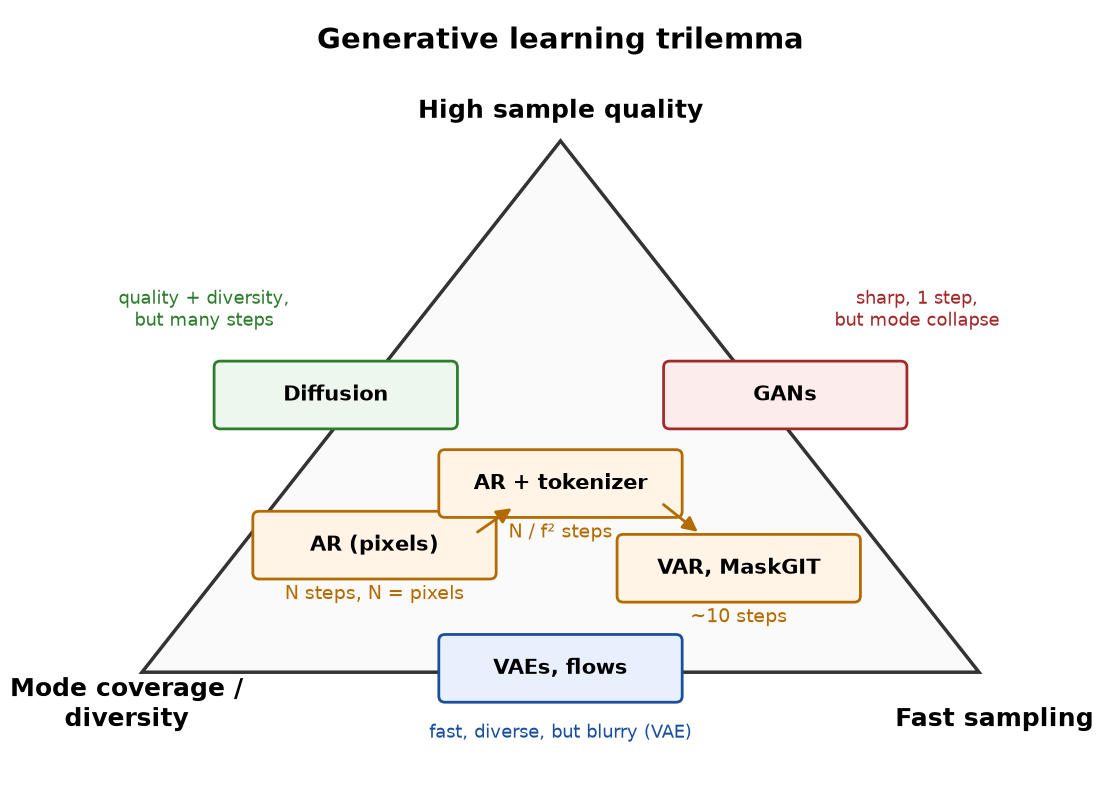

- GAN: качественные образцы за один проход, но склонность к коллапсу мод — часть распределения не генерируется вообще.
- VAE и потоки: быстрые и покрывают моды (обучение на правдоподобии), но образцы VAE размыты.
- Диффузия: качество и разнообразие, но сэмплинг требует многих шагов; в исходной работе DDPM во всех экспериментах $T = 1000$ шагов ([Ho et al., 2020](https://arxiv.org/abs/2006.11239)).
- Авторегрессионные модели: точное правдоподобие, хорошее покрытие мод и качество. Цена — последовательный сэмплинг: $N$ проходов сети на изображение, и $N$ растёт с разрешением.

Почти всё, о чём идёт речь дальше, — способы сдвинуть авторегрессионную модель к третьей вершине, не теряя двух других. Токенизатор сокращает $N$ в $f^2$ раз. Параллельное декодирование (MaskGIT) и предсказание следующего масштаба (VAR) сокращают число шагов при той же длине. Сэмплинг с temperature, top-k и top-p сдвигает баланс между качеством и разнообразием уже после обучения.

## 4. VAE

### 4.1. Устройство

VAE ([Kingma, Welling, 2013](https://arxiv.org/abs/1312.6114)) делает ELBO обучаемым градиентным спуском. Энкодер выдаёт параметры гауссианы $q_\phi(z|x) = \mathcal{N}(\mu_\phi(x), \operatorname{diag}\sigma^2_\phi(x))$, приор — $p(z) = \mathcal{N}(0, I)$. KL между двумя гауссианами считается аналитически:

$
\mathrm{KL} = \frac{1}{2} \sum_j \left(\mu_j^2 + \sigma_j^2 - 1 - \log \sigma_j^2\right).
$

Математическое ожидание реконструкции оценивается одним сэмплом $z$, но сэмплирование недифференцируемо. Трюк репараметризации выносит случайность наружу: $z = \mu + \sigma \odot \varepsilon$, $\varepsilon \sim \mathcal{N}(0, I)$. Теперь $z$ — дифференцируемая функция $\mu$ и $\sigma$, и градиент проходит в энкодер.

### 4.2. Почему VAE размывает

Если декодер — гауссиана с фиксированной дисперсией, $\log p_\theta(x|z)$ с точностью до константы равен $-\|x - \hat x(z)\|^2$. При шумном $z$ одному и тому же коду соответствуют несколько правдоподобных изображений (цифра чуть левее, чуть правее), и минимизатор средней квадратичной ошибки — их среднее. Среднее нескольких резких изображений размыто. Это свойство не архитектуры, а функции потерь: пиксельная MSE не различает «размытое, но в среднем верное» и «резкое, но сдвинутое на пиксель». Раздел 7 (VQGAN) решает ту же проблему для токенизаторов.

### 4.3. β-VAE и posterior collapse

[β-VAE](https://openreview.net/forum?id=Sy2fzU9gl) умножает KL на $\beta$. При $\beta > 1$ латент становится «чище» (координаты независимее) ценой реконструкции; при $\beta < 1$ реконструкция лучше, но сэмплы из приора хуже: агрегированное апостериорное распределение отходит от $\mathcal{N}(0, I)$.

Posterior collapse — вырожденное решение, при котором $q_\phi(z|x) = p(z)$ для всех $x$: KL равен нулю, латент не несёт информации, а декодер моделирует данные сам. [Bowman et al. (2016)](https://arxiv.org/abs/1511.06349) наблюдали это у VAE с LSTM-декодером для текста: большинство запусков сводили KL к нулю, и модель вела себя как обычная языковая модель. Чем мощнее декодер (авторегрессионный декодер может смоделировать $x$ без всякого $z$), тем выше риск. Частичный коллапс — когда неактивна часть координат латента — встречается и у сверточных VAE. Лекарства: разогрев веса KL от 0 до 1, ослабление декодера, ограничение снизу на KL по каждой координате. И дискретный латент VQ-VAE.

## 5. VQ-VAE

### 5.1. Дискретный латент

VQ-VAE ([van den Oord et al., 2017](https://arxiv.org/abs/1711.00937)) заменяет непрерывный латент дискретным. Энкодер выдаёт карту векторов $z_e(x) \in \mathbb{R}^{h \times w \times D}$. Каждый вектор заменяется ближайшим из обучаемого codebook $\mathcal{C} = \{e_1, \dots, e_K\}$:

$
k^* = \arg\min_k \|z_e - e_k\|_2, \qquad z_q = e_{k^*}.
$

Изображение превращается в сетку $h \times w$ номеров кодов — визуальных токенов. Декодер восстанавливает изображение по $z_q$. Приор в VQ-VAE обучаемый, а не фиксированный: после обучения автоэнкодера отдельная авторегрессионная модель учит распределение сеток токенов. В исходной работе это PixelCNN; изображения ImageNet 128×128×3 кодировались сеткой 32×32 при $K = 512$.

Как VAE, VQ-VAE имеет детерминированное апостериорное распределение (one-hot на $k^*$) и равномерный приор при обучении автоэнкодера. KL тогда равен константе $\log K$, и ELBO сводится к реконструкции. Posterior collapse невозможен: декодер получает только $z_q$, и игнорировать его нельзя.

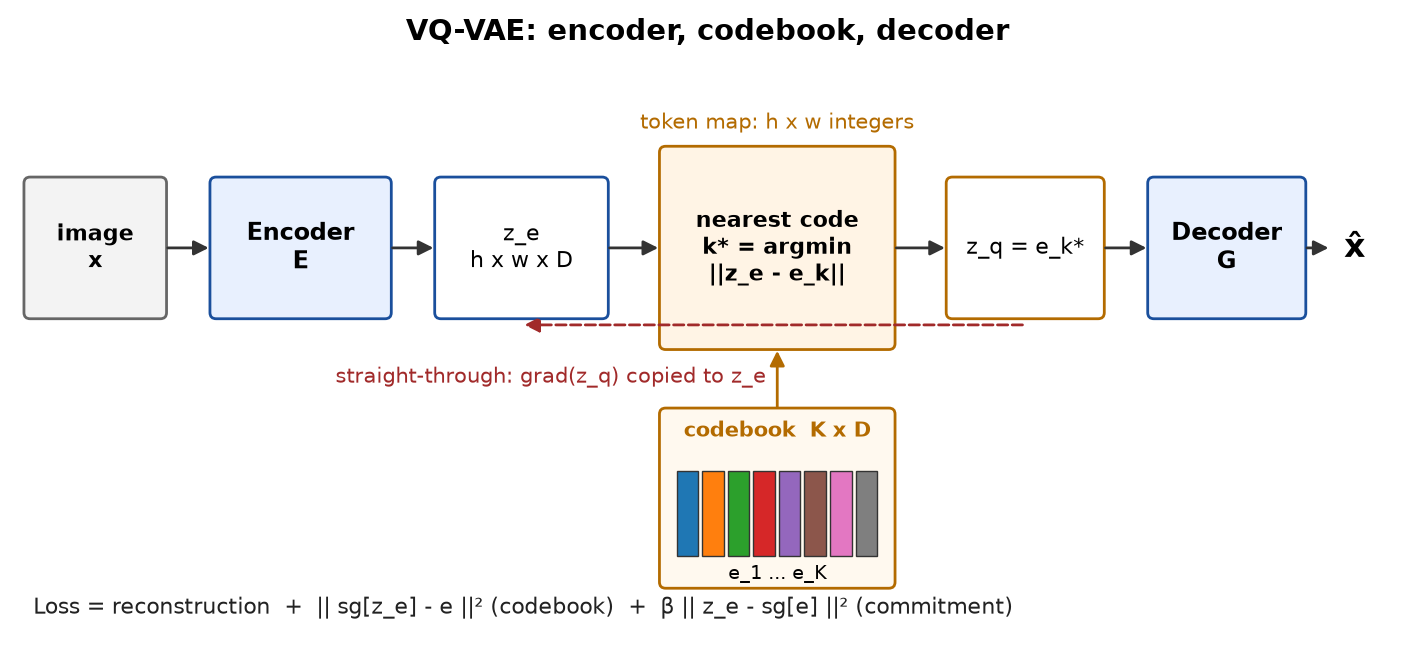

### 5.2. Потеря и stop-gradient

$
\mathcal{L} = \underbrace{-\log p(x \mid z_q)}_{\text{reconstruction}} + \underbrace{\|\mathrm{sg}[z_e] - e\|_2^2}_{\text{codebook loss}} + \underbrace{\beta\,\|z_e - \mathrm{sg}[e]\|_2^2}_{\text{commitment loss}}.
$

Здесь $\mathrm{sg}[\cdot]$ — stop-gradient: в прямом проходе тождество, в обратном — нулевой градиент. Слагаемые обновляют разные части модели:

- реконструкция обучает декодер и (через straight-through estimator) энкодер;
- codebook loss двигает выбранные коды $e$ к выходам энкодера, а энкодер не трогает. Это онлайновый вариант k-means;
- commitment loss тянет выход энкодера к выбранному коду, а коды не трогает. Без него выходы энкодера могут неограниченно расти или «перескакивать» между кодами, и codebook не успевает за ними.

Авторы использовали $\beta = 0{,}25$ и отмечали, что результаты мало менялись при $\beta$ от 0,1 до 2.

Распространённая альтернатива codebook loss — обновление кодов экспоненциальным скользящим средним (EMA): каждый код сдвигается к среднему назначенных ему векторов энкодера, как шаг k-means со сглаживанием. EMA обычно стабильнее и не зависит от learning rate оптимизатора.

### 5.3. Straight-through estimator

Операция $\arg\min$ кусочно-постоянна: градиент по $z_e$ почти везде равен нулю. Straight-through estimator (STE) делает вид, что квантования не было: градиент по $z_q$ копируется на $z_e$ без изменений. В коде это одна строка:

```python
z_q = z_e + (q - z_e).detach()   # значение = q, градиент по z_e = градиент по z_q
```

Оценка смещённая: она игнорирует то, что маленький сдвиг $z_e$ может сменить ближайший код. Работает она потому, что commitment loss держит $z_e$ рядом с $z_q$, и градиент декодера в точке $z_q$ хорошо приближает градиент в точке $z_e$. [Fifty et al. (2024)](https://arxiv.org/abs/2410.06424) предложили rotation trick: вместо простого копирования градиент «поворачивается» линейным преобразованием, переводящим $z_e$ в $z_q$, и несёт информацию об угле и норме между ними. По их данным, это улучшает использование codebook и реконструкцию в 11 вариантах обучения VQ-VAE.

## 6. Коллапс кодов

### 6.1. Механизм

Коллапс codebook — ситуация, когда используется лишь малая доля кодов, а остальные «мертвы». [Jukebox](https://arxiv.org/pdf/2005.00341) описывает его так: все выходы энкодера отображаются в один или несколько кодов, остальные не используются, и информационная ёмкость узкого места падает. Механизм следует прямо из формул раздела 5:

1. Код получает градиент только через codebook loss и только если он ближайший хотя бы для одного вектора энкодера (STE codebook не обновляет).
2. Если в начале обучения часть кодов оказалась далеко от облака выходов энкодера, они не выбираются, не обновляются и не приближаются — навсегда.
3. Выбранные коды, наоборот, тянутся к данным, становятся ещё ближе и ещё чаще выбираются. Энкодер через commitment loss подстраивается под них. Это положительная обратная связь.

Чем больше $K$ и чем выше размерность кодов $D$, тем сильнее эффект: в высокой размерности случайно инициализированные векторы почти все одинаково далеки от данных.

### 6.2. Как измерять

- Использование (usage): доля кодов, которые встретились хотя бы раз на достаточно большой выборке.
- Перплексия: $2^{H(p)}$, где $p$ — эмпирическое распределение кодов. Это «эффективное число кодов»: $K$ при равномерном использовании, 1 при полном коллапсе. Её удобно логировать на каждом шаге.

### 6.3. Лекарства

| Приём | Идея | Источник |
|---|---|---|
| Инициализация данными, k-means | коды стартуют внутри облака выходов энкодера | распространённая практика |
| Перезапуск мёртвых кодов | если среднее использование кода ниже порога, код заменяется случайным выходом энкодера из текущего батча | [Jukebox](https://arxiv.org/pdf/2005.00341) |
| EMA-обновление кодов | стабильное онлайновое k-means вместо градиента | [van den Oord et al., 2017](https://arxiv.org/abs/1711.00937) |
| Низкоразмерные нормированные коды | поиск ближайшего в пространстве размерности 8–32 после проекции; коды и выходы энкодера нормируются, расстояние становится косинусным | [ViT-VQGAN](https://arxiv.org/pdf/2110.04627) |
| FSQ | вместо codebook — округление каждой координаты к фиксированной решётке уровней; неявный codebook $\prod_i L_i$ | [Mentzer et al., 2023](https://arxiv.org/abs/2309.15505) |
| LFQ | размерность кода $\log_2 K$, каждая координата квантуется в $\{-1, 1\}$ знаком; энтропийный штраф за неравномерное использование | [MAGVIT-v2](https://arxiv.org/pdf/2310.05737) |

Масштаб эффекта в ViT-VQGAN: при $K = 8192$ и нормированных кодах снижение размерности поиска с 256 до 32 подняло использование codebook с 4% до 96%, а без нормировки при размерности 32 использовалось лишь 2% кодов ([Yu et al., 2021](https://arxiv.org/pdf/2110.04627)). FSQ использует почти все коды даже при размере $2^{14}$ без вспомогательных потерь, тогда как у обычного VQ использование падает ниже 50% для codebook больше $2^{11}$ ([Mentzer et al., 2023](https://arxiv.org/pdf/2309.15505)). В MAGVIT-v2 LFQ позволил поднять словарь до $K = 2^{18}$. С ростом словаря у LFQ улучшались и реконструкция, и генерация; у VQ генерация сначала улучшалась, потом ухудшалась ([Yu et al., 2023](https://arxiv.org/pdf/2310.05737)).

Энтропийный штраф LFQ записывается как $\mathcal{L}_{\text{entropy}} = \mathbb{E}[H(q(z))] - H(\mathbb{E}[q(z)])$. Первое слагаемое делает выбор кода для каждого вектора уверенным, второе (со знаком минус) требует, чтобы в среднем по батчу коды использовались равномерно.

## 7. VQGAN

[VQGAN](https://arxiv.org/abs/2012.09841) (Esser, Rombach, Ommer, 2021) — VQ-VAE, обученный так, чтобы токенов было мало, а реконструкция оставалась резкой. Две добавки к функции потерь:

- перцептивная потеря: реконструкция сравнивается с оригиналом не только попиксельно, но и в пространстве признаков предобученной сети (LPIPS), $\mathcal{L}_{\text{rec}} = \|x - \hat x\|^2 + \|\phi(x) - \phi(\hat x)\|^2$;
- adversarial-потеря с патч-дискриминатором (PatchGAN): дискриминатор оценивает реалистичность каждого фрагмента, и декодер учится рисовать правдоподобную текстуру вместо усреднённой.

Полная потеря $\mathcal{L} = \mathcal{L}_{\text{rec}} + \mathcal{L}_{\text{codebook}} + \lambda\,\mathcal{L}_{\text{GAN}}$, где вес подбирается адаптивно по градиентам на последнем слое декодера $G_L$:

$
\lambda = \frac{\|\nabla_{G_L} \mathcal{L}_{\text{rec}}\|}{\|\nabla_{G_L} \mathcal{L}_{\text{GAN}}\| + \delta}, \qquad \delta = 10^{-6}.
$

Смысл: adversarial-градиент всегда масштабируется до величины реконструкционного, и ни одна потеря не подавляет другую, как бы ни менялись их абсолютные значения за обучение. Дискриминатор включают не с первого шага: сначала автоэнкодер должен научиться грубой реконструкции.

Благодаря этим потерям VQGAN держит качество при сильном сжатии: изображение 256×256 при $f = 16$ кодируется сеткой 16×16, то есть 256 токенами, с codebook обычно на 1024 или 16 384 кода ([Esser et al., 2021](https://arxiv.org/pdf/2012.09841)). Вторая часть работы — трансформер, который авторегрессионно генерирует эти токены (раздел 10).

## 8. Длина последовательности и пространственное сжатие

### 8.1. Три числа токенизатора

Пусть токенизатор уменьшает каждую сторону изображения в $f$ раз (spatial compression factor, коэффициент пространственного сжатия) и использует codebook из $K$ кодов. Тогда для изображения $H \times W$:

$
N = \frac{H}{f}\cdot\frac{W}{f}, \qquad \text{rate} = N \log_2 K \ \text{бит на изображение}.
$

- $N$ — длина последовательности для генератора. Self-attention стоит $O(N^2)$ по памяти и времени на слой, а авторегрессионный сэмплинг требует $N$ последовательных шагов.
- $\log_2 K$ — сколько бит несёт один токен; при $K = 16\,384$ это 14 бит.
- rate — информационная ёмкость всего представления. Всё, что в неё не поместилось, декодер обязан «дорисовать».

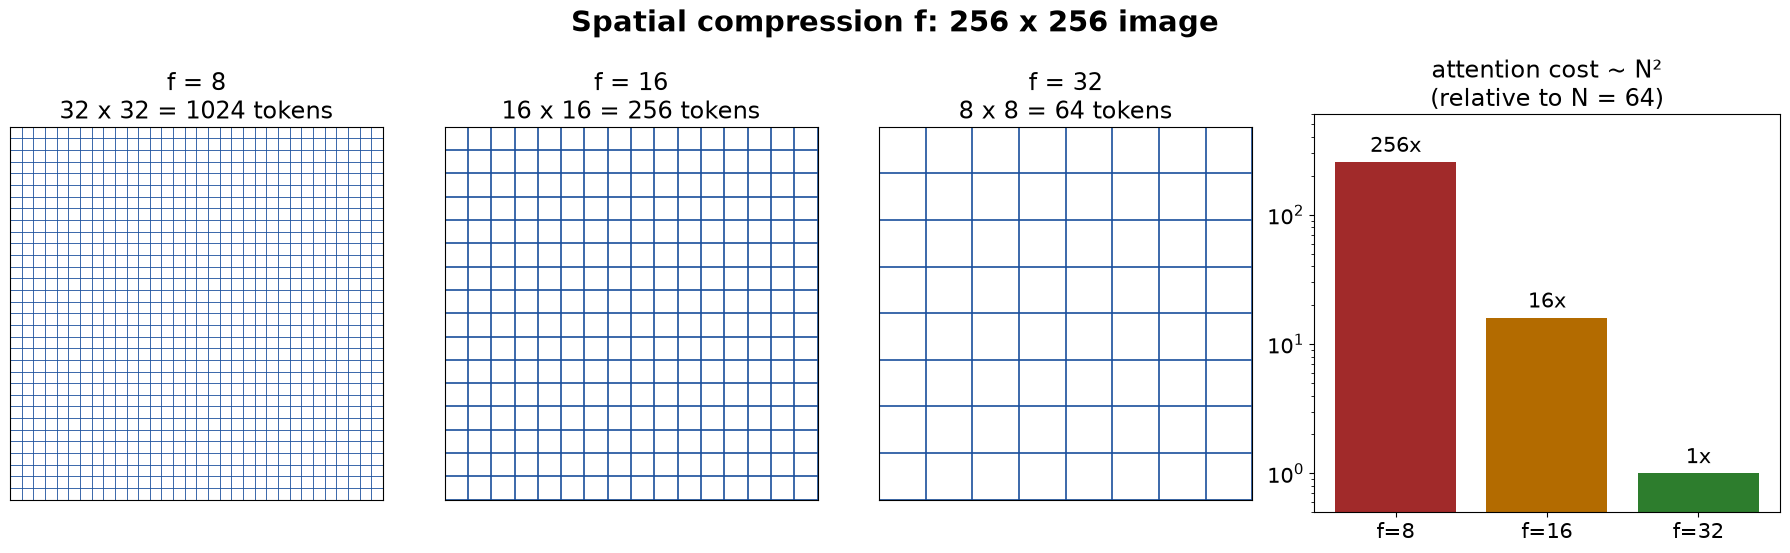

Изображение 256×256 при $f = 8$ даёт 1024 токена, при $f = 16$ — 256, при $f = 32$ — 64. Переход от $f = 16$ к $f = 8$ удлиняет последовательность в 4 раза, а стоимость внимания — в 16 раз.

### 8.2. Компромисс: реконструкция против генерации

Маленькое $f$ даёт хорошую реконструкцию, но длинную и «низкоуровневую» последовательность: приор тратит ёмкость на текстуры. Большое $f$ даёт короткую семантическую последовательность, но теряет детали. В работе о латентной диффузии сравнивались $f \in \{1, 2, 4, 8, 16, 32\}$, и значения от 4 до 16 названы хорошим компромиссом между эффективностью и качеством ([Rombach et al., 2022](https://arxiv.org/pdf/2112.10752)).

Измерения LlamaGen показывают ту же зависимость на реконструкции (rFID, ниже лучше) при $K = 16\,384$ ([Sun et al., 2024](https://arxiv.org/html/2406.06525)):

| Токенизатор | Разрешение | Сетка токенов | rFID |
|---|---|---|---|
| $f = 16$ | 256 | 16×16 = 256 | 2,19 |
| $f = 16$ | 384 | 24×24 = 576 | 0,94 |
| $f = 16$ | 512 | 32×32 = 1024 | 0,70 |
| $f = 8$ | 256 | 32×32 = 1024 | 0,59 |

Видно, что качество определяется прежде всего числом токенов: 1024 токена дают близкий rFID и при $f = 8$ на 256, и при $f = 16$ на 512.

### 8.3. Как сократить последовательность, не теряя качества

- Поднять $K$ и при этом не допустить коллапса (раздел 6): больше бит на токен при той же длине.
- Перцептивная и adversarial-потери (VQGAN, раздел 7): декодер дорисовывает правдоподобную текстуру, и токенам не нужно её хранить.
- Одномерные токенизаторы. TiTok кодирует изображение 256×256 в 32 токена вместо 256 или 1024 у двумерных токенизаторов и получает gFID 1,97 на ImageNet 256; на 512×512 генерация в 410 раз быстрее DiT ([Yu et al., 2024](https://arxiv.org/abs/2406.07550)). Токены здесь уже не привязаны к позициям сетки.
- Иерархии масштабов (VQ-VAE-2, VAR): грубые уровни несут структуру, тонкие — детали (раздел 10.5).

## 9. Токенизаторы в современных VLM и генераторах

### 9.1. Понимание и генерация требуют разного

Для понимания (VLM: описание, VQA) изображение превращают в последовательность непрерывных векторов. Обычно это выходы ViT-энкодера (CLIP, SigLIP), спроецированные в пространство LLM (лекции 5–6). Энкодер обучен на семантике, а квантование только потеряло бы информацию.

Для генерации нужно уметь выдавать изображение по одному токену, поэтому выход должен быть дискретным (softmax по $K$ кодам) и обратимым (декодер восстанавливает пиксели). Отсюда VQ-токенизаторы с codebook.

Это противоречие хорошо видно в Janus: модель использует для понимания энкодер SigLIP-Large-Patch16-384, а для генерации — отдельный VQ-токенизатор с $K = 16\,384$ и $f = 16$. Оба потока подаются в один авторегрессионный трансформер ([Wu et al., 2024](https://arxiv.org/pdf/2410.13848)). Авторы называют это разделением визуального кодирования (decoupling): один общий энкодер вынужден был бы обслуживать и семантику, и детали пикселей.

### 9.2. Параметры известных токенизаторов

Эти значения используются в практикуме (раздел 19).

| Система | Вход | Сжатие и сетка | Словарь | Назначение | Источник |
|---|---|---|---|---|---|
| VQ-VAE | ImageNet 128×128 | 32×32 | 512 | дискретный латент, приор PixelCNN | [van den Oord et al., 2017](https://arxiv.org/abs/1711.00937) |
| DALL-E (dVAE) | 256×256 | 32×32 = 1024 | 8192 | генерация по тексту, до 256 текстовых BPE-токенов + 1024 токена изображения | [Ramesh et al., 2021](https://arxiv.org/pdf/2102.12092v2) |
| VQGAN | 256×256 | $f = 16$, 16×16 = 256 | 1024 или 16 384 | AR-трансформер | [Esser et al., 2021](https://arxiv.org/pdf/2012.09841) |
| ViT-VQGAN | 256×256 | патчи 8×8, 32×32 = 1024 | 8192 | AR-трансформер, Parti | [Yu et al., 2021](https://arxiv.org/pdf/2110.04627) |
| LlamaGen | 256–512 | $f = 16$ или 8 | 16 384, коды размерности 8 | AR на архитектуре Llama | [Sun et al., 2024](https://arxiv.org/html/2406.06525) |
| Chameleon | 512×512 | 1024 токена | 8192 | смешанно-модальная LLM | [Chameleon Team, 2024](https://arxiv.org/pdf/2405.09818) |
| Emu3 | 512×512 | $f = 8$, 4096 токенов | 32 768 | генерация следующего токена, также видео (4× по времени) | [Wang et al., 2024](https://arxiv.org/html/2409.18869) |
| Janus | 384×384 | $f = 16$, 24×24 = 576 | 16 384 (генерация); SigLIP (понимание) | раздельные энкодеры | [Wu et al., 2024](https://arxiv.org/pdf/2410.13848) |
| Stable Diffusion VAE | 512×512 | $f = 8$, 64×64×4 | непрерывный | латентная диффузия | [Rombach et al., 2022](https://arxiv.org/pdf/2112.10752) |
| Qwen2-VL | 224×224 | патч 14 + слияние 2×2, 66 токенов со служебными | непрерывный | понимание | [Wang et al., 2024](https://arxiv.org/html/2409.12191) |

Строка MaskGIT в таблице практикума ($f = 16$, $K = 1024$) взята по аналогии с VQGAN-токенизатором; число кодов в оригинальной статье здесь отдельно не проверялось.

Общая тенденция: словари выросли с 512–1024 до $10^4$–$10^5$ кодов, а коллапс стали лечить на уровне устройства квантователя (низкоразмерные нормированные коды, FSQ, LFQ). В LlamaGen при $K = 16\,384$, кодах размерности 8 и l2-нормировке использование словаря составило 97% ([Sun et al., 2024](https://arxiv.org/html/2406.06525)).

## 10. Авторегрессионные приоры

### 10.1. Общая схема

Авторегрессионная (AR) модель раскладывает совместное распределение по цепному правилу:

$
p(x_1, \dots, x_N) = \prod_{i=1}^{N} p(x_i \mid x_{<i}).
$

Каждый множитель — softmax над словарём; обучение — кросс-энтропия на следующем токене с учительским форсированием (teacher forcing, на вход подаются истинные предыдущие токены). Правдоподобие точное, поэтому модель напрямую оценивается в bits/dim. Цена — $N$ последовательных шагов сэмплинга.

Двухэтапная схема токенизатор + приор: (1) обучить токенизатор и заморозить его; (2) закодировать датасет в последовательности индексов; (3) обучить AR-модель на индексах; (4) сэмплировать индексы и декодировать их в пиксели.

### 10.2. От пикселей к токенам

- PixelRNN и PixelCNN ([van den Oord et al., 2016](https://arxiv.org/abs/1601.06759)) моделируют пиксели по одному в растровом порядке; PixelCNN использует маскированные свёртки, чтобы пиксель видел только уже сгенерированных соседей. Условный вариант с классом или эмбеддингом — Conditional PixelCNN ([van den Oord et al., 2016](https://arxiv.org/abs/1606.05328)).
- ImageGPT ([Chen et al., 2020](https://cdn.openai.com/papers/Generative_Pretraining_from_Pixels_V2.pdf)) — GPT-2 на пикселях. Чтобы сократить словарь и длину, цвета квантуются k-means в 9-битную палитру (512 цветов), что в 3 раза короче, чем три канала RGB. Разрешения 32², 48², 64²; модели от 76 млн (iGPT-S) до 6,8 млрд (iGPT-XL) параметров. Даже на 64×64 последовательность — 4096 токенов, и это главный предел пиксельной авторегрессии.
- VQ-VAE ([van den Oord et al., 2017](https://arxiv.org/abs/1711.00937)) и VQ-VAE-2 ([Razavi et al., 2019](https://arxiv.org/abs/1906.00446)) обучают PixelCNN-приор уже на сетке кодов, а не на пикселях.
- VQGAN-Transformer ([Esser et al., 2021](https://arxiv.org/pdf/2012.09841)) заменяет PixelCNN трансформером на 256 токенах; изображения больше 1024 токенов генерируются скользящим окном, сэмплинг — с top-k.
- DALL-E ([Ramesh et al., 2021](https://arxiv.org/pdf/2102.12092v2)) склеивает текстовые и визуальные токены в одну последовательность; Parti ([Yu et al., 2022](https://arxiv.org/abs/2206.10789)) — seq2seq-трансформер до 20 млрд параметров поверх ViT-VQGAN.
- LlamaGen ([Sun et al., 2024](https://arxiv.org/html/2406.06525)) показывает, что обычная архитектура LLM (Llama, 111 млн — 3,1 млрд параметров) без специальных визуальных индуктивных смещений достигает FID 2,18 на ImageNet 256.

### 10.3. Classifier-free guidance в авторегрессии

Условную модель обучают, с вероятностью 0,1 заменяя условие (класс, текст) на «пустое». На сэмплинге на каждом шаге считают условные и безусловные логиты и экстраполируют:

$
\ell_g = \ell_u + s\,(\ell_c - \ell_u),
$

где $s > 1$ — масштаб guidance ([Ho & Salimans, 2022](https://arxiv.org/abs/2207.12598)). В LlamaGen лучшие результаты при $s$ около 1,75–2,0, с T = 1, без top-k и с top-p = 1 ([Sun et al., 2024](https://arxiv.org/html/2406.06525)). Guidance повышает качество и соответствие условию ценой разнообразия, поэтому вместе с ним обычно не ставят агрессивного обрезания распределения.

### 10.4. Порядок генерации

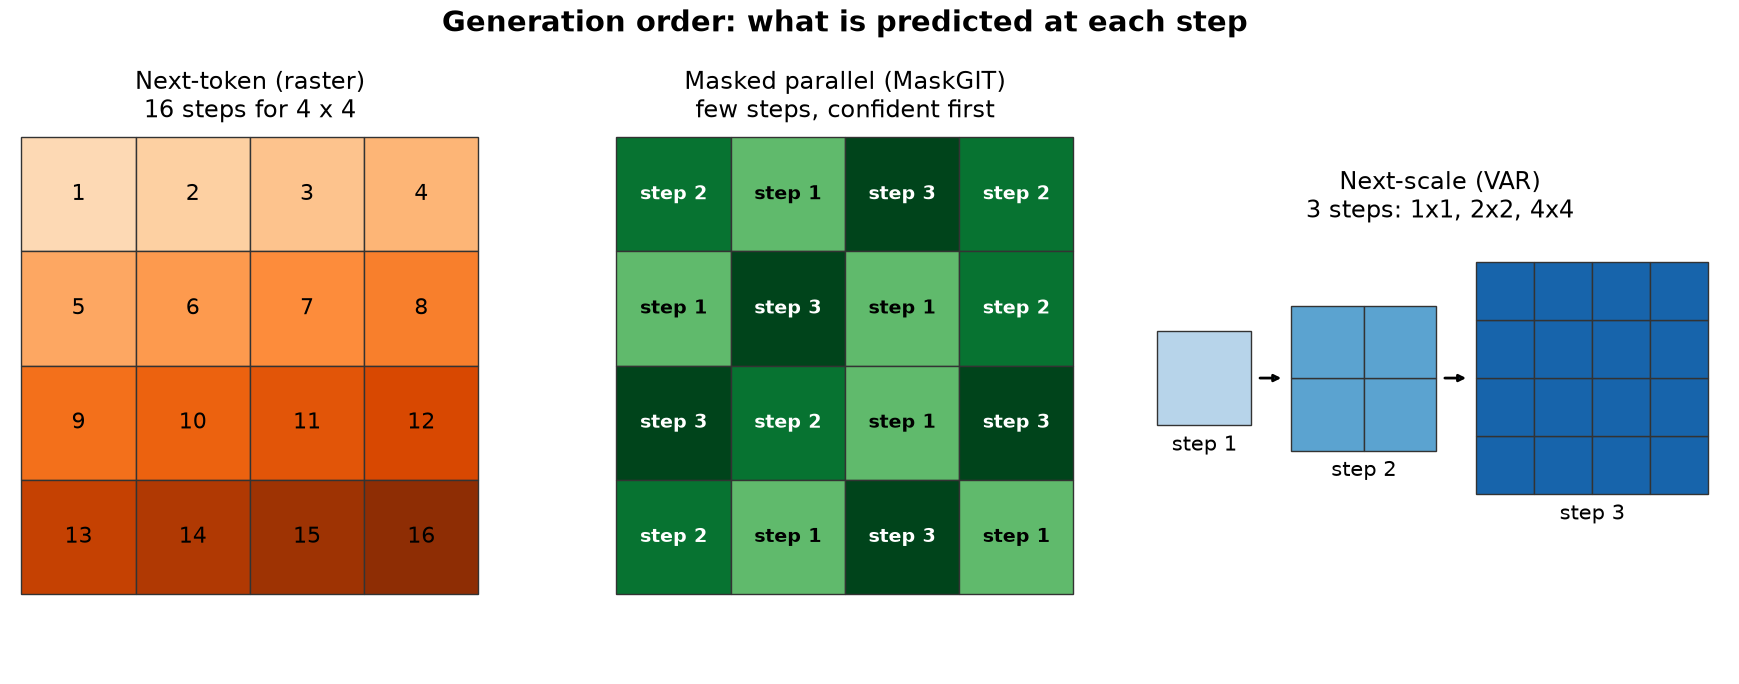

Растровый порядок (raster scan, слева направо, сверху вниз) удобен, но произволен: у изображения нет «начала». Две альтернативы:

- Маскированное параллельное декодирование, MaskGIT ([Chang et al., 2022](https://arxiv.org/pdf/2202.04200)). Двунаправленный трансформер учится восстанавливать случайно замаскированные токены. На сэмплинге за шаг предсказываются все маскированные позиции, оставляются самые уверенные, остальные снова маскируются. Около 8 шагов вместо 256 (на 512×512 — 12 вместо 1024), в 30–64 раза быстрее авторегрессии. Платой является потеря точного правдоподобия.
- Предсказание следующего масштаба (next-scale prediction), VAR, — раздел 10.5.

### 10.5. VAR: next-scale prediction

VAR ([Tian et al., 2024](https://arxiv.org/abs/2404.02905)) меняет единицу авторегрессии: вместо токена — целая карта токенов следующего разрешения:

$
p(r_1, \dots, r_K) = \prod_{k=1}^{K} p(r_k \mid r_1, \dots, r_{k-1}),
$

где $r_k$ — карта $h_k \times w_k$. Все токены одной карты генерируются параллельно.

Токенизатор — многомасштабный VQ (multi-scale VQ) с общим словарём $V = 4096$ и сжатием 16×. Квантование остаточное: на масштабе $k$ признаковая карта уменьшается до $h_k \times w_k$ и квантуется. Результат увеличивается до полного размера, проходит через небольшую свёртку $\phi_k$ и вычитается из остатка. Сумма всех уровней даёт латент для декодера. По умолчанию масштабы 1, 2, 3, 4, 5, 6, 8, 10, 13, 16, всего 680 токенов на изображение 256×256 ([код VAR](https://raw.githubusercontent.com/FoundationVision/VAR/main/utils/arg_util.py)).

Трансформер обучается за один проход с блочно-причинной маской (block-causal): токены масштаба $k$ видят все токены масштабов $\le k-1$ и друг друга в пределах своего уровня ([Tian et al., 2024](https://arxiv.org/abs/2404.02905)). Вход для масштаба $k$ — увеличенная до $h_k \times w_k$ уже накопленная карта. На инференсе используется KV-кэш, маска не нужна: за шаг обрабатываются только новые позиции текущего масштаба.

Почему это быстрее. Для сетки $n \times n$ обычная авторегрессия делает $O(n^2)$ последовательных шагов и $O(n^6)$ вычислений, VAR — $O(\log n)$ шагов и $O(n^4)$ вычислений. На ImageNet 256 VAR улучшил FID с 18,65 у AR-базовой линии до 1,73 и IS с 80,4 до 350,2 при примерно в 20 раз более быстром инференсе. Сэмплинг — 10 шагов с top-k 600 и CFG; качество подчиняется степенному закону масштабирования с корреляцией около −0,998 ([Tian et al., 2024](https://arxiv.org/abs/2404.02905)). Работа получила Best Paper NeurIPS 2024 ([репозиторий VAR](https://github.com/FoundationVision/VAR)).

## 11. Сэмплинг: температура, top-k, top-p

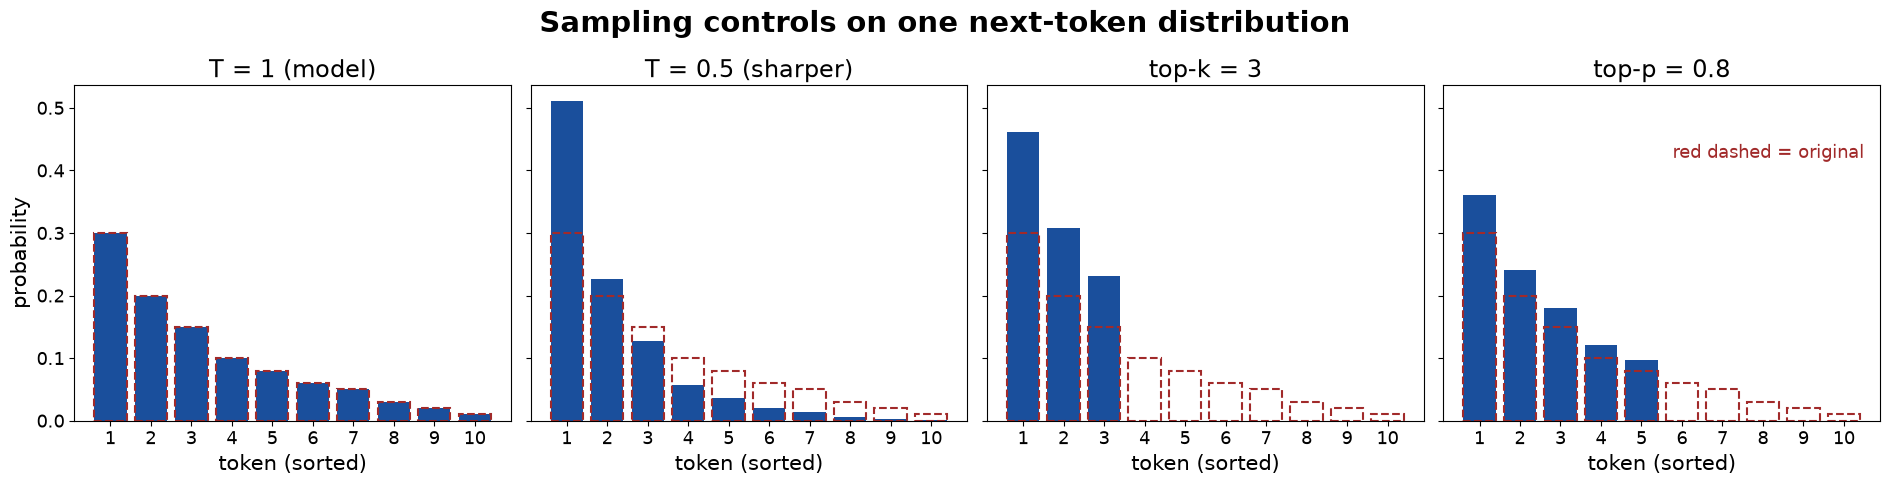

Модель выдаёт логиты $\ell \in \mathbb{R}^K$. Как из них выбрать токен — отдельное решение, сильно влияющее на результат.

### 11.1. Greedy и почему он плох

Greedy decoding — брать $\arg\max$. Для изображений это почти всегда вырождение: однотонный фон, повторяющиеся текстуры, одинаковые сэмплы. Причина: самый вероятный следующий токен — «продолжить то, что уже есть». Произведение локально максимальных вероятностей не даёт типичного изображения, и разнообразие обнуляется. Для текста этот эффект описан как повторы и деградация ([Holtzman et al., 2019](https://arxiv.org/abs/1904.09751)).

### 11.2. Температура

$
p_i(T) = \frac{\exp(\ell_i / T)}{\sum_j \exp(\ell_j / T)}.
$

$T \to 0$ — greedy, $T = 1$ — распределение модели, $T > 1$ — более плоское распределение: больше разнообразия и больше «мусорных» токенов из хвоста. Температура меняет форму всего распределения, но не отрезает хвост.

### 11.3. Top-k

Оставить $k$ самых вероятных токенов, остальным поставить вероятность 0 и перенормировать. Восходит к работам по генерации историй ([Fan et al., 2018](https://arxiv.org/abs/1805.04833)); в VQGAN и VAR это основной способ ([Esser et al., 2021](https://arxiv.org/pdf/2012.09841), [Tian et al., 2024](https://arxiv.org/abs/2404.02905)). Недостаток — фиксированное $k$ не учитывает форму распределения: при уверенном предсказании пропускается мусор, при неуверенном отрезаются разумные варианты ([Holtzman et al., 2019](https://arxiv.org/abs/1904.09751)).

### 11.4. Top-p (nucleus sampling)

Оставить наименьшее множество $V^{(p)}$ самых вероятных токенов, суммарная вероятность которого не меньше $p$:

$
\sum_{i \in V^{(p)}} p_i \ge p, \qquad p'_i = \frac{p_i}{\sum_{j \in V^{(p)}} p_j}\ \text{при}\ i \in V^{(p)}, \text{иначе } 0.
$

Размер «ядра» адаптируется: при пиковом распределении это 1–2 токена, при плоском — сотни. Обычно $p \in [0{,}9;\ 1)$, в исходной работе $p = 0{,}95$ ([Holtzman et al., 2019](https://arxiv.org/abs/1904.09751)).

### 11.5. Порядок применения и типичные настройки

Порядок в коде: логиты → CFG (если есть) → деление на $T$ → top-k → top-p → softmax → сэмпл. Ориентиры из статей:

| Модель | Настройки |
|---|---|
| VAR | top-k 600, CFG ([Tian et al., 2024](https://arxiv.org/abs/2404.02905)) |
| LlamaGen | T = 1, top-k = весь словарь, top-p = 1, CFG 1,75–2,0 ([Sun et al., 2024](https://arxiv.org/html/2406.06525)) |
| VQGAN-Transformer | top-k ([Esser et al., 2021](https://arxiv.org/pdf/2012.09841)) |

Важно: эти приёмы меняют распределение, из которого берутся сэмплы. Правдоподобие модели (bpd) от них не зависит, но FID, разнообразие и соответствие условию — зависят. Настройки сэмплинга подбирают на валидации, как гиперпараметры.

## 12. Оценка генеративных моделей

### 12.1. Метрики

| Метрика | Что измеряет | Ограничения |
|---|---|---|
| NLL, bits/dim | точное правдоподобие (AR, потоки) или его оценку (ELBO у VAE) | высокое правдоподобие не гарантирует хороших сэмплов, и наоборот ([Theis et al., 2016](https://arxiv.org/abs/1511.01844)); несравнимо между токенами и пикселями |
| FID | расстояние Фреше между гауссовыми аппроксимациями признаков Inception реальных и сгенерированных изображений ([Heusel et al., 2017](https://arxiv.org/abs/1706.08500)) | зависит от числа сэмплов и от сети-экстрактора; смешивает качество и разнообразие |
| IS | уверенность классификатора и разнообразие классов | не сравнивает с реальными данными |
| Precision / Recall | доля сэмплов в области данных (качество) и доля области данных, покрытая сэмплами (разнообразие) ([Kynkäänniemi et al., 2019](https://arxiv.org/abs/1904.06991)) | чувствительны к выбору $k$ в kNN |
| rFID | FID реконструкций токенизатора | верхняя граница качества всей системы |
| gFID | FID сгенерированных изображений | то, что видит пользователь |
| usage, perplexity codebook | здоровье токенизатора (раздел 6.2) | не говорит о качестве реконструкции |

rFID и gFID нужно различать: хороший токенизатор — необходимое, но не достаточное условие. Слишком «информативный» токенизатор (длинная последовательность, огромный словарь) может дать отличный rFID и при этом трудную для приора задачу. В MAGVIT-v2 у VQ с ростом словаря генерация сначала улучшалась, а потом ухудшалась ([Yu et al., 2023](https://arxiv.org/pdf/2310.05737)).

В практикуме вместо FID используется расстояние Фреше на признаках маленького классификатора MNIST (FD). Его абсолютные значения несравнимы с опубликованными FID, только между нашими моделями.

### 12.2. Рецепт

1. Выбрать бюджет длины $N$ под приор и железо, отсюда $f$.
2. Обучить токенизатор: VQ с перцептивной и adversarial-потерями, нормированные низкоразмерные коды или FSQ/LFQ; следить за usage и perplexity с первого шага.
3. Проверить реконструкцию (rFID, PSNR) на отложенной выборке и только потом заморозить токенизатор.
4. Обучить приор на индексах, следить за валидационной кросс-энтропией.
5. Подобрать сэмплинг (T, top-k/top-p, CFG) по gFID и precision/recall на валидации.

### 12.3. Типичные ошибки

- Не логировать usage codebook и обнаружить коллапс только по плохой генерации.
- Сравнивать bits/dim модели на токенах с bits/dim модели на пикселях: это разные случайные величины.
- Подбирать сэмплинг «на глаз» по нескольким картинкам вместо метрик на тысячах сэмплов.
- Считать FID на малом числе сэмплов и сравнивать его с опубликованными значениями на 50 тыс.
- Считать, что маленький rFID автоматически даёт маленький gFID.
- Забыть про условие в VAR и авторегрессии: если при обучении условие не заменялось на пустое, безусловных логитов нет и CFG применить нельзя.

# Часть II. Практикум

## 13. Подготовка: среда, данные, модель-оценщик

### 13.1. Задача практикума

Весь путь лекции пройдём на одном наборе данных — MNIST ([LeCun et al.](https://yann.lecun.org/exdb/mnist/index.html)), дополненном до 32×32. Набор маленький, поэтому на CPU за минуты обучается всё, о чём говорилось в теории: VAE, три варианта VQ-VAE, токенизаторы с разной степенью сжатия, VQGAN-подобная модель, пиксельный авторегрессор в духе ImageGPT, трансформер по кодам и мини-VAR с предсказанием следующего масштаба. Цифры легко узнать глазами, и по ним надёжно работает классификатор-оценщик. Масштаб другой, чем в статьях, но механизмы те же: коллапс кодов, потолок качества, который задаёт токенизатор, рост стоимости с длиной последовательности, влияние temperature, top-k и top-p.

План практикума:

| Раздел | Что делаем | Что увидим |
|---|---|---|
| 13 | среда, данные, классификатор-оценщик, метрики | FD, точность класса, разнообразие |
| 14 | правдоподобие: пиксели в палитре, независимая модель | bits/dim как общая шкала |
| 15 | VAE | ELBO, размытость, β и неактивные латенты |
| 16 | VQ-VAE с нуля | STE, commitment loss, коллапс кодов и его лечение, FSQ |
| 17 | степень сжатия f | длина последовательности, биты на изображение, PSNR и rFD |
| 18 | VQGAN-lite | перцептивная и adversarial-потери, адаптивный вес λ |
| 19 | предобученный токенизатор TAESD | латент Stable Diffusion на реальной фотографии |
| 20 | пиксельный авторегрессор (ImageGPT в миниатюре) | точный bits/dim, 256 шагов генерации |
| 21 | трансформер по кодам VQ (VQGAN-Transformer) | 64 шага, класс как условие |
| 22 | temperature, top-k, top-p | компромисс качество–разнообразие |
| 23 | мини-VAR | 4 шага вместо 64 |
| 24 | сводная таблица | генеративная трилемма в цифрах |

### 13.2. Режимы запуска

В Colab с GPU (`Runtime → Change runtime type → T4 GPU`) все модели обучаются дольше, трансформеры шире и выборки для оценки больше. На CPU автоматически включается `FAST_DEV_RUN`: шагов обучения меньше в 3–7 раз, трансформеры уже ($d = 128$ вместо 192; у пиксельной модели $d = 96$ и 3 слоя), для оценки генерируется 200 изображений вместо 1000. Все числа в тексте практикума взяты из сохранённого CPU-прогона. На GPU значения будут другими (обычно лучше), поэтому переносить стоит выводы о направлении эффектов, а не сами числа. Путь с GPU исполнением не проверялся.

In [1]:
import importlib.util, subprocess, sys
# В Colab torch, torchvision и scipy уже установлены; diffusers нужен только для раздела 19.
for pkg in ["diffusers"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

In [2]:
import os, io, math, time, json, random, platform, urllib.request
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from scipy import linalg

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FAST_DEV_RUN = DEVICE == "cpu"
torch.set_num_threads(max(1, os.cpu_count() or 1))

S = dict(  # число шагов оптимизатора и размеры оценочных выборок
    bs=128, steps_cls=500, steps_vae=3000, steps_vq=4000, steps_f=4000, steps_gan=6000,
    steps_pix=6000, bs_pix=64, d_pix=128, L_pix=4, steps_ar=6000, steps_var=6000, d_ar=192, n_eval=1000)
if FAST_DEV_RUN:
    S.update(bs=64, steps_cls=800, steps_vae=1000, steps_vq=1200, steps_f=1200, steps_gan=1500,
             steps_pix=800, bs_pix=32, d_pix=96, L_pix=3, steps_ar=1500, steps_var=1500, d_ar=128, n_eval=200)

def seed_all(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_all(0)

print("python", platform.python_version(), "| torch", torch.__version__, "| torchvision", torchvision.__version__)
print("device:", DEVICE, "| FAST_DEV_RUN:", FAST_DEV_RUN, "| threads:", torch.get_num_threads())
print(S)

python 3.12.13 | torch 2.14.1+cpu | torchvision 0.29.1+cpu
device: cpu | FAST_DEV_RUN: True | threads: 2
{'bs': 64, 'steps_cls': 800, 'steps_vae': 1000, 'steps_vq': 1200, 'steps_f': 1200, 'steps_gan': 1500, 'steps_pix': 800, 'bs_pix': 32, 'd_pix': 96, 'L_pix': 3, 'steps_ar': 1500, 'steps_var': 1500, 'd_ar': 128, 'n_eval': 200}


### 13.3. Данные

MNIST: 60 000 обучающих и 10 000 тестовых изображений 28×28 в оттенках серого. Дополняем нулями до 32×32, чтобы размеры делились на 2, 4 и 8: это нужно для токенизаторов с разной степенью сжатия. Значения пикселей лежат в [0, 1]. Все данные помещаются в память как один тензор.

train (60000, 1, 32, 32) test (10000, 1, 32, 32) range (0.0, 1.0)


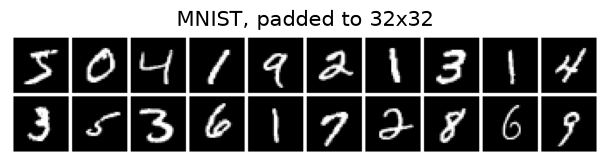

In [3]:
tr = torchvision.datasets.MNIST("data", train=True, download=True)
te = torchvision.datasets.MNIST("data", train=False, download=True)
def to_tensor(ds):
    x = ds.data.float().div(255).unsqueeze(1)
    return F.pad(x, (2, 2, 2, 2)), ds.targets.clone()
Xtr, Ytr = to_tensor(tr); Xte, Yte = to_tensor(te)
print("train", tuple(Xtr.shape), "test", tuple(Xte.shape), "range", (Xtr.min().item(), Xtr.max().item()))

def batches(X, Y, bs, steps, seed=0):
    g = torch.Generator().manual_seed(seed)
    for _ in range(steps):
        i = torch.randint(0, len(X), (bs,), generator=g)
        yield X[i].to(DEVICE), Y[i].to(DEVICE)

def show(imgs, nrow=10, title=None, scale=1.0, labels=None):
    imgs = imgs.detach().float().cpu().clamp(0, 1)
    n = len(imgs); ncol = math.ceil(n / nrow)
    grid = torchvision.utils.make_grid(imgs, nrow=nrow, padding=2, pad_value=1.0)
    plt.figure(figsize=(scale * nrow * 0.62, scale * ncol * 0.62 + (0.5 if title else 0)))
    plt.imshow(grid.permute(1, 2, 0).numpy(), cmap="gray"); plt.axis("off")
    if title: plt.title(title, fontsize=15)
    plt.tight_layout(); plt.show()

def psnr(x, y):
    mse = F.mse_loss(x.clamp(0, 1), y, reduction="none").flatten(1).mean(1)
    return (10 * torch.log10(1 / mse.clamp_min(1e-10))).mean().item()

class Timer:
    def __enter__(self):
        if torch.cuda.is_available(): torch.cuda.synchronize()
        self.t = time.time(); return self
    def __exit__(self, *a):
        if torch.cuda.is_available(): torch.cuda.synchronize()
        self.s = time.time() - self.t

show(Xtr[:20], title="MNIST, padded to 32x32")

### 13.4. Классификатор-оценщик и метрики генерации

Генеративные модели будем сравнивать тремя числами, и все три считает один и тот же маленький классификатор, обученный на реальных данных:

- FD (Fréchet distance) — расстояние Фреше между гауссианами, подогнанными к признакам реальных и сгенерированных изображений. Это та же формула, что у FID ([Heusel et al., 2017](https://arxiv.org/abs/1706.08500)), но признаки берутся не из Inception, а из нашего классификатора. Поэтому числа нельзя сравнивать с FID из статей, а между моделями этого блокнота — можно. Меньше — лучше.
- Точность класса (acc) — доля сгенерированных изображений, которые классификатор относит к запрошенному классу. Имеет смысл только для моделей с условием на класс. Это мера соответствия условию.
- Разнообразие (div) — средняя попарная дистанция признаков внутри класса, делённая на ту же величину для реальных изображений. Значение 1 означает «разнообразно, как реальные данные», около 0 — «одно и то же изображение». Для безусловных моделей класс берётся из предсказания классификатора.

Ещё одна вспомогательная величина — уверенность классификатора (conf, средняя максимальная вероятность): неразборчивые цифры дают низкую уверенность.

In [4]:
class Clf(nn.Module):
    def __init__(self):
        super().__init__()
        self.f = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.head = nn.Linear(128, 10)
    def forward(self, x): return self.head(self.f(x))

seed_all(0)
clf = Clf().to(DEVICE); opt = torch.optim.Adam(clf.parameters(), 2e-3)
with Timer() as t:
    for x, y in batches(Xtr, Ytr, S["bs"], S["steps_cls"], seed=1):
        loss = F.cross_entropy(clf(x), y); opt.zero_grad(); loss.backward(); opt.step()
clf.eval().requires_grad_(False)

@torch.no_grad()
def clf_out(x, bs=500):
    fs, ps = [], []
    for i in range(0, len(x), bs):
        xb = x[i:i + bs].to(DEVICE).float().clamp(0, 1)
        f = clf.f(xb); fs.append(f.cpu()); ps.append(clf.head(f).softmax(-1).cpu())
    return torch.cat(fs).double().numpy(), torch.cat(ps)

def frechet(fa, fb):
    mu1, mu2 = fa.mean(0), fb.mean(0); s1, s2 = np.cov(fa, rowvar=False), np.cov(fb, rowvar=False)
    covmean = linalg.sqrtm(s1 @ s2)
    if isinstance(covmean, tuple): covmean = covmean[0]
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * covmean.real))

def within_class_spread(f, cls):
    vals = []
    for c in range(10):
        fc = torch.from_numpy(f[cls == c])
        if len(fc) >= 2: vals.append(torch.pdist(fc).mean().item())
    return float(np.mean(vals))

F_TE, P_TE = clf_out(Xte)
print(f"classifier: {t.s:.0f} s, test accuracy {(P_TE.argmax(1) == Yte).float().mean():.4f}")
g = torch.Generator().manual_seed(0)
REF_IDX = torch.randperm(len(Xte), generator=g)[:S["n_eval"]]   # реальная выборка того же размера
SPREAD_REAL = within_class_spread(F_TE[REF_IDX], Yte[REF_IDX].numpy())

def evaluate(x, y=None):
    """FD к 10 000 тестовых изображений, acc (если задан класс), conf, div."""
    f, p = clf_out(x); pred = p.argmax(1)
    cls = (y.cpu() if y is not None else pred).numpy()
    r = dict(FD=frechet(f, F_TE), conf=p.max(1).values.mean().item(),
             div=within_class_spread(f, cls) / SPREAD_REAL)
    if y is not None: r["acc"] = (pred == y.cpu()).float().mean().item()
    return r

def fmt(r): return "  ".join(f"{k}={v:.3f}" if k != "FD" else f"FD={v:.2f}" for k, v in r.items())
base_real = evaluate(Xte[REF_IDX], Yte[REF_IDX])
print("real test sample:", fmt(base_real))

classifier: 29 s, test accuracy 0.9393
real test sample: FD=3.07  conf=0.928  div=1.000  acc=0.930


/tmp/ipykernel_3714/3260384558.py:28: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = linalg.sqrtm(s1 @ s2)


Что видно. Классификатор-оценщик на тесте даёт точность 0,939. Реальная тестовая выборка из 200 изображений задаёт ориентир: FD = 3,07, а не ноль (FD смещён на малых выборках: 200 изображений хуже описывают распределение, чем 10 000), уверенность 0,928, точность 0,930, разнообразие по определению 1,000. Сгенерированные изображения будем сравнивать именно с этой строкой, а не с нулём.

## 14. Правдоподобие и bits/dim

### 14.1. Пиксели как дискретные символы

Чтобы правдоподобие было точной дискретной величиной, переведём изображения в символы, как это делает ImageGPT: уменьшим до 16×16 (среднее по блокам 2×2) и заменим каждый пиксель номером ближайшего цвета из палитры. Палитру строим k-means по значениям пикселей; в ImageGPT это 512 кластеров в пространстве RGB ([Chen et al., 2020](https://cdn.openai.com/papers/Generative_Pretraining_from_Pixels_V2.pdf)), у нас 8 оттенков серого. Изображение превращается в последовательность из 256 символов алфавита размера 8.

Bits/dim — средняя отрицательная логарифмическая вероятность одного символа в битах: $\text{bpd} = -\frac{1}{D}\log_2 p(x)$, где $D = 256$. Это длина кода, которую дал бы идеальный арифметический кодер, построенный на модели. Верхняя граница — $\log_2 8 = 3$ бита, если считать все цвета равновероятными.

palette: [0.    0.062 0.147 0.256 0.391 0.554 0.751 0.948]
bits/dim on test: uniform 3.000 | one histogram 1.185 | independent pixels 0.844


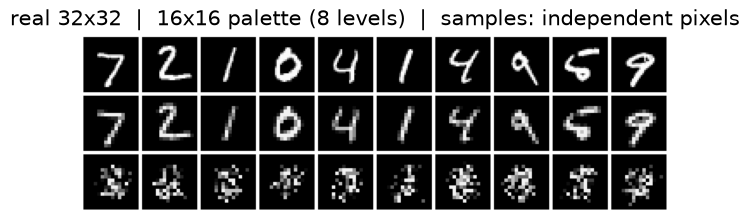

In [5]:
PAL_K = 8
def kmeans_1d(v, k, iters=30, seed=0):
    rng = np.random.default_rng(seed); c = np.sort(rng.choice(v, k, replace=False))
    for _ in range(iters):
        a = np.abs(v[:, None] - c[None]).argmin(1)
        c = np.array([v[a == j].mean() if (a == j).any() else c[j] for j in range(k)])
    return np.sort(c)

X16tr, X16te = F.avg_pool2d(Xtr, 2), F.avg_pool2d(Xte, 2)
sample = X16tr[:2000].flatten().numpy()
PALETTE = torch.tensor(kmeans_1d(sample, PAL_K), dtype=torch.float32)
def to_pal(x16): return (x16.flatten(1)[..., None] - PALETTE).abs().argmin(-1)        # B, 256
def from_pal(idx): return PALETTE[idx.cpu()].view(-1, 1, 16, 16)
Ptr, Pte = to_pal(X16tr), to_pal(X16te)
print("palette:", np.round(PALETTE.numpy(), 3))

# Модель 0: все 8 цветов равновероятны.  Модель 1: независимые пиксели, своё распределение у каждой позиции.
LN2 = math.log(2)
counts = torch.stack([torch.bincount(Ptr[:, j], minlength=PAL_K) for j in range(256)]).float() + 1.0
p_pos = counts / counts.sum(1, keepdim=True)                                         # 256 x 8
bpd_indep = -(torch.log(p_pos[torch.arange(256), Pte]).sum(1).mean() / 256 / LN2).item()
p_glob = torch.bincount(Ptr.flatten(), minlength=PAL_K).float() + 1; p_glob /= p_glob.sum()
bpd_glob = -(torch.log(p_glob[Pte]).mean() / LN2).item()
print(f"bits/dim on test: uniform {math.log2(PAL_K):.3f} | one histogram {bpd_glob:.3f} | independent pixels {bpd_indep:.3f}")

rt = F.interpolate(from_pal(Pte[:10]), size=32, mode="nearest")
ind = torch.multinomial(p_pos, 10, replacement=True).T                                 # 10 x 256
show(torch.cat([Xte[:10], rt, F.interpolate(from_pal(ind), size=32, mode="nearest")]),
     title="real 32x32  |  16x16 palette (8 levels)  |  samples: independent pixels")

Что видно. Палитра из 8 уровней сохраняет цифры узнаваемыми (вторая строка), поэтому потери от дискретизации невелики. Равномерная модель тратит $\log_2 8 = 3$ бита на пиксель, одна общая гистограмма — 1,185 бита, модель независимых пикселей — 0,844 бита: она знает, что края изображения почти всегда чёрные. Но её сэмплы (третья строка) — шум в центре: она не знает, что соседние пиксели связаны. Правдоподобие на тесте у неё приличное, а образцы плохие. Это первая иллюстрация того, что bits/dim и качество образцов измеряют разное. В разделе 20 авторегрессионный трансформер на тех же символах снизит bits/dim ещё сильнее, и мы проверим, стали ли от этого лучше образцы.

## 15. VAE: непрерывный латент

### 15.1. Общие блоки энкодера и декодера

Все автоэнкодеры практикума (VAE, VQ-VAE, VQGAN-lite, мини-VAR) используют одни и те же сверточные блоки. Энкодер уменьшает разрешение в $f$ раз ($\log_2 f$ сверток с шагом 2), на нижнем разрешении стоит остаточный блок, на выходе — карта $D$ каналов размера $\frac{32}{f} \times \frac{32}{f}$. Декодер зеркален: остаточный блок и транспонированные свертки. Сети намеренно маленькие (0,1–0,4 млн параметров), чтобы весь практикум проходил на CPU. Декодер выдаёт логиты пикселей, яркость получается сигмоидой.

In [6]:
class ResBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.b = nn.Sequential(nn.GroupNorm(8, c), nn.SiLU(), nn.Conv2d(c, c, 3, padding=1),
                               nn.GroupNorm(8, c), nn.SiLU(), nn.Conv2d(c, c, 3, padding=1))
    def forward(self, x): return x + self.b(x)

CH = [16, 32, 64, 64]          # каналы на разрешениях 32, 16, 8, 4; сеть намеренно маленькая, чтобы обучаться на CPU
class Encoder(nn.Module):
    def __init__(self, f, D):
        super().__init__(); n = int(math.log2(f))
        layers = [nn.Conv2d(1, CH[0], 3, padding=1), nn.SiLU()]
        for i in range(n): layers += [nn.Conv2d(CH[i], CH[i + 1], 4, 2, 1), nn.SiLU()]
        layers += [ResBlock(CH[n]), nn.GroupNorm(8, CH[n]), nn.SiLU(), nn.Conv2d(CH[n], D, 1)]
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

class Decoder(nn.Module):
    def __init__(self, f, D):
        super().__init__(); n = int(math.log2(f))
        layers = [nn.Conv2d(D, CH[n], 3, padding=1), ResBlock(CH[n])]
        for i in reversed(range(n)): layers += [nn.ConvTranspose2d(CH[i + 1], CH[i], 4, 2, 1), nn.SiLU()]
        self.net = nn.Sequential(*layers); self.out = nn.Conv2d(CH[0], 1, 3, padding=1)   # out — «последний слой» для VQGAN
    def forward(self, z): return self.out(self.net(z))     # логиты пикселей

def n_params(*ms): return sum(p.numel() for m in ms for p in m.parameters())
print("encoder f=4, D=16:", n_params(Encoder(4, 16)), "params; decoder:", n_params(Decoder(4, 16)))

encoder f=4, D=16: 116496 params; decoder: 124545


### 15.2. Обучение VAE и роль β

Латент VAE — карта 4×4×4, то есть 64 непрерывных числа ($f = 8$). Энкодер выдаёт среднее и логарифм дисперсии для каждого числа, латент сэмплируется через трюк репараметризации $z = \mu + \sigma \odot \varepsilon$. Потеря — отрицательный ELBO в натах на изображение: бинарная кросс-энтропия реконструкции плюс $\beta \cdot \mathrm{KL}(q(z|x)\,\|\,\mathcal{N}(0, I))$. Обучим две модели: обычный VAE ($\beta = 1$) и $\beta = 4$.

Латентная координата считается активной, если её средний KL на тесте больше 0,01 ната: неактивная координата не несёт информации об изображении (энкодер выдаёт для неё приор) — это частичный posterior collapse.

Оговорка: BCE по яркостям из [0, 1] — не настоящее дискретное правдоподобие, поэтому ELBO здесь не переводим в bits/dim и с разделом 14 не сравниваем.

In [7]:
class VAE(nn.Module):
    def __init__(self, zc=4):
        super().__init__(); self.zc = zc
        self.enc, self.dec = Encoder(8, 2 * zc), Decoder(8, zc)
    def forward(self, x):
        mu, logvar = self.enc(x).chunk(2, 1)
        z = mu + torch.randn_like(mu) * (0.5 * logvar).exp()
        rec = F.binary_cross_entropy_with_logits(self.dec(z), x, reduction="none").flatten(1).sum(1)
        kl = 0.5 * (mu ** 2 + logvar.exp() - 1 - logvar)                       # B, zc, 4, 4
        return rec, kl
    @torch.no_grad()
    def sample(self, n): return self.dec(torch.randn(n, self.zc, 4, 4, device=DEVICE)).sigmoid()

def train_vae(beta, steps, seed=0):
    seed_all(seed); m = VAE().to(DEVICE); opt = torch.optim.Adam(m.parameters(), 1e-3)
    for x, _ in batches(Xtr, Ytr, S["bs"], steps, seed=seed + 10):
        rec, kl = m(x); loss = (rec + beta * kl.flatten(1).sum(1)).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    m.eval()
    with torch.no_grad():
        xb = Xte[:2000].to(DEVICE); rec, kl = m(xb)
        mu, _ = m.enc(xb).chunk(2, 1); recon = m.dec(mu).sigmoid()
    kl_dim = kl.mean(0).flatten()
    return m, dict(rec=rec.mean().item(), kl=kl.flatten(1).sum(1).mean().item(),
                   active=int((kl_dim > 0.01).sum()), psnr=psnr(recon.cpu(), Xte[:2000]))

VAES = {}
for beta in [1.0, 4.0]:
    with Timer() as t: m, r = train_vae(beta, S["steps_vae"])
    VAES[beta] = m
    r.update(evaluate(m.sample(S["n_eval"]))); r["time_s"] = t.s
    print(f"beta={beta}: rec={r['rec']:.1f} nats  KL={r['kl']:.1f} nats  active latents {r['active']}/64  "
          f"PSNR={r['psnr']:.2f}  samples: {fmt({k: r[k] for k in ['FD', 'conf', 'div']})}  ({t.s:.0f} s)")
    VAES[f"r{beta}"] = r

/tmp/ipykernel_3714/3260384558.py:28: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = linalg.sqrtm(s1 @ s2)


beta=1.0: rec=85.3 nats  KL=28.0 nats  active latents 42/64  PSNR=21.39  samples: FD=117.17  conf=0.635  div=0.805  (60 s)


beta=4.0: rec=130.6 nats  KL=7.6 nats  active latents 16/64  PSNR=17.14  samples: FD=202.01  conf=0.600  div=0.669  (60 s)


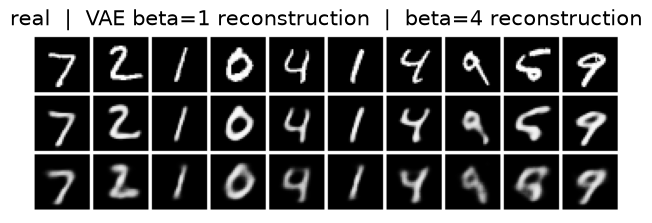

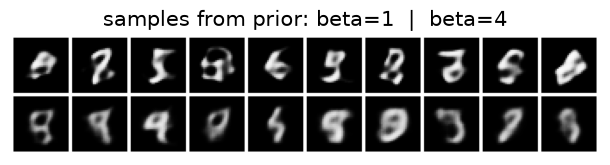

In [8]:
with torch.no_grad():
    mu, _ = VAES[1.0].enc(Xte[:10].to(DEVICE)).chunk(2, 1); rec1 = VAES[1.0].dec(mu).sigmoid()
    mu, _ = VAES[4.0].enc(Xte[:10].to(DEVICE)).chunk(2, 1); rec4 = VAES[4.0].dec(mu).sigmoid()
show(torch.cat([Xte[:10], rec1.cpu(), rec4.cpu()]), title="real  |  VAE beta=1 reconstruction  |  beta=4 reconstruction")
seed_all(1)
show(torch.cat([VAES[1.0].sample(10).cpu(), VAES[4.0].sample(10).cpu()]), title="samples from prior: beta=1  |  beta=4")

Что видно. При $\beta = 1$ KL равен 28,0 ната, активны 42 из 64 координат латента, PSNR реконструкции 21,39 дБ. Реконструкции узнаваемы, но размыты: при гауссовом шуме в латенте декодер, минимизирующий ожидаемую ошибку, выдаёт усреднение нескольких правдоподобных изображений. Рост $\beta$ до 4 покупает «гладкость» латента ценой информации: KL падает до 7,6 ната, активных координат остаётся 16, PSNR падает до 17,14 дБ, а FD образцов растёт со 117 до 202. Генерация у VAE мгновенная (один проход декодера), но образцы из приора размыты и часто не похожи на цифры: уверенность классификатора 0,635 против 0,928 у реальных данных. Это одна вершина генеративной трилеммы: скорость есть, качества нет.

## 16. VQ-VAE с нуля

### 16.1. Слой квантования

Слой ниже — прямая запись формул раздела 5. Для каждого вектора энкодера $z_e$ ищется ближайший код $e_k$ в codebook из $K$ векторов. Потеря VQ-VAE ([van den Oord et al., 2017](https://arxiv.org/abs/1711.00937)) состоит из двух слагаемых. Codebook loss $\|\mathrm{sg}[z_e] - e\|^2$ двигает код к выходу энкодера. Commitment loss $\beta\|z_e - \mathrm{sg}[e]\|^2$ с $\beta = 0{,}25$ не даёт выходу энкодера уходить от кодов. Градиент через argmin проходит straight-through estimator: `z_q = z_e + (q - z_e).detach()`.

Режимы инициализации и обслуживания codebook:

- `init="uniform"` — коды из $U(-1/K, 1/K)$, как в распространённых реализациях: все коды почти в нуле;
- `init="data"` — коды инициализируются случайными выходами энкодера с первого батча;
- `restart=True` — «мёртвые» коды (скользящее среднее числа попаданий меньше 3% от среднего по codebook) заменяются случайными выходами энкодера из текущего батча, как в Jukebox.

Реконструкционная потеря — бинарная кросс-энтропия по логитам декодера (пиксели MNIST почти бинарны). С MSE после сигмоиды декодер при сильном сжатии ($f = 8$) в нашем CPU-прогоне застревал на чёрном изображении: сигмоида насыщается, и градиент MSE через неё исчезает. MSE мы по-прежнему записываем в журнал обучения, а PSNR считаем по ней.

Метрики codebook: использование (usage) — доля кодов, которые встретились хотя бы раз на 2000 тестовых изображений; перплексия — $2^{H}$, где $H$ — энтропия распределения кодов в битах. Перплексия равна «эффективному числу кодов»: $K$ при равномерном использовании, 1 — если используется один код.

In [9]:
class VQ(nn.Module):
    def __init__(self, K, D, beta=0.25, init="uniform", restart=False):
        super().__init__()
        self.K, self.D, self.beta, self.restart = K, D, beta, restart
        self.E = nn.Parameter(torch.empty(K, D).uniform_(-1 / K, 1 / K))
        self.register_buffer("ema", torch.zeros(K)); self.register_buffer("ready", torch.tensor(init != "data"))
    def nearest(self, flat):
        d = flat.pow(2).sum(1, keepdim=True) - 2 * flat @ self.E.t() + self.E.pow(2).sum(1)
        return d.argmin(1)
    def lookup(self, idx): return self.E[idx].movedim(-1, 1)          # B,H,W -> B,D,H,W
    def forward(self, z):
        B, D, H, W = z.shape; flat = z.movedim(1, -1).reshape(-1, D)
        if self.training and not self.ready:
            self.E.data.copy_(flat[torch.randperm(len(flat), device=flat.device)[:self.K]].detach()); self.ready.fill_(True)
        idx = self.nearest(flat); q = self.E[idx]
        loss = F.mse_loss(q, flat.detach()) + self.beta * F.mse_loss(flat, q.detach())
        if self.training:
            with torch.no_grad():
                self.ema.mul_(0.99).add_(0.01 * torch.bincount(idx, minlength=self.K).float())
                if self.restart:
                    dead = self.ema < 0.03 * len(flat) / self.K       # меньше 3% от среднего числа попаданий
                    if dead.any():
                        self.E.data[dead] = flat[torch.randint(0, len(flat), (int(dead.sum()),), device=flat.device)].detach()
                        self.ema[dead] = 2.0
        q = flat + (q - flat).detach()                                        # straight-through estimator
        return q.view(B, H, W, D).movedim(-1, 1), idx.view(B, H, W), loss

class FSQ(nn.Module):
    """Finite scalar quantization: каждую координату округляем к одному из L_i уровней."""
    def __init__(self, levels):
        super().__init__()
        self.register_buffer("L", torch.tensor(levels, dtype=torch.float32))
        self.register_buffer("basis", torch.tensor(np.cumprod([1] + levels[:-1]), dtype=torch.long))
        self.K, self.D = int(np.prod(levels)), len(levels)
    def bound(self, z):
        L = self.L.view(1, -1, 1, 1); half = (L - 1) * (1 - 1e-3) / 2
        offset = torch.where(L % 2 == 0, 0.5, 0.0); shift = torch.atanh(offset / half)
        return torch.tanh(z + shift) * half - offset
    def forward(self, z):
        zb = self.bound(z); zq = zb + (torch.round(zb) - zb).detach()          # округление через STE
        half = (self.L // 2).view(1, -1, 1, 1)
        idx = ((zq.detach() + half).long() * self.basis.view(1, -1, 1, 1)).sum(1)
        return zq / half, idx, torch.zeros((), device=z.device)               # без codebook и commitment loss
    def lookup(self, idx):
        digits = (idx[:, None] // self.basis.view(1, -1, 1, 1)) % self.L.long().view(1, -1, 1, 1)
        half = (self.L // 2).view(1, -1, 1, 1)
        return (digits.float() - half) / half

class VQAE(nn.Module):
    def __init__(self, f, quant):
        super().__init__(); self.f, self.q = f, quant
        self.enc, self.dec = Encoder(f, quant.D), Decoder(f, quant.D)
    def forward(self, x):
        zq, idx, qloss = self.q(self.enc(x)); return self.dec(zq), idx, qloss
    @torch.no_grad()
    def encode(self, x): return self.q(self.enc(x.to(DEVICE)))[1]
    @torch.no_grad()
    def decode(self, idx): return self.dec(self.q.lookup(idx.to(DEVICE))).sigmoid()

def code_stats(idx, K):
    c = torch.bincount(idx.flatten().cpu(), minlength=K).float(); p = c / c.sum()
    H = -(p[p > 0] * p[p > 0].log2()).sum().item()
    return dict(usage=(c > 0).float().mean().item(), perplexity=2 ** H)

@torch.no_grad()
def eval_tokenizer(m, n=2000):
    m.eval(); idx = torch.cat([m.encode(Xte[i:i + 500]).cpu() for i in range(0, n, 500)])
    rec = torch.cat([m.decode(idx[i:i + 500]).cpu() for i in range(0, n, 500)])
    r = dict(psnr=psnr(rec, Xte[:n]), **code_stats(idx, m.q.K))
    f, p = clf_out(rec); r["rFD"] = frechet(f, F_TE); r["rec_acc"] = (p.argmax(1) == Yte[:n]).float().mean().item()
    return r

def train_vqae(f, quant, steps, seed=0, log_every=100, lr=1e-3):
    seed_all(seed); m = VQAE(f, quant).to(DEVICE); opt = torch.optim.Adam(m.parameters(), lr); hist = []
    for step, (x, _) in enumerate(batches(Xtr, Ytr, S["bs"], steps, seed=seed + 20)):
        logits, idx, qloss = m(x); loss = F.binary_cross_entropy_with_logits(logits, x) + qloss
        rec = F.mse_loss(logits.sigmoid(), x).detach()                 # MSE только для журнала
        opt.zero_grad(); loss.backward(); opt.step()
        if step % log_every == 0 or step == steps - 1:
            hist.append(dict(step=step, rec=rec.item(), **code_stats(idx, quant.K)))
    return m.eval(), hist

### 16.2. Проверка straight-through estimator

Убедимся, что приём `z + (q - z).detach()` делает именно то, что обещает: в прямом проходе значение равно $q$, а градиент по $z_e$ совпадает с градиентом по $z_q$, как если бы квантования не было.

In [10]:
torch.manual_seed(0)
vq_test = VQ(K=8, D=4); vq_test.E.data.normal_()
z = torch.randn(2, 4, 3, 3, requires_grad=True)
zq, idx, _ = vq_test(z)
w = torch.randn_like(zq); (zq * w).sum().backward()                    # dL/dz_q = w
print("forward value equals nearest code:", torch.allclose(zq, vq_test.lookup(idx)))
print("dL/dz_e equals dL/dz_q:          ", torch.allclose(z.grad, w))
print("codebook gets gradient from STE?  ", vq_test.E.grad is not None and vq_test.E.grad.abs().sum().item() > 0)

forward value equals nearest code: True
dL/dz_e equals dL/dz_q:           True
codebook gets gradient from STE?   False


Что видно. Значение — ближайший код, а градиент копируется на выход энкодера без изменений. Codebook через этот путь градиента не получает (`False`): коды учатся только через codebook loss. Поэтому код, к которому никто не ближе остальных, не получает обновлений вообще — отсюда механизм «мёртвых» кодов.

### 16.3. Три токенизатора: наивный VQ, VQ с перезапуском, FSQ

Сравним три способа дискретизации при одинаковых энкодере и декодере ($f = 4$, сетка 8×8 = 64 токена):

| Вариант | Codebook | Обслуживание |
|---|---|---|
| naive VQ | $K = 256$, $D = 16$, равномерная инициализация около нуля | нет |
| VQ + restart | $K = 256$, $D = 16$, инициализация данными | перезапуск мёртвых кодов |
| FSQ | уровни (8, 6, 5), неявный codebook $K = 240$, $D = 3$ | не нужно ([Mentzer et al., 2023](https://arxiv.org/abs/2309.15505)) |

In [11]:
TOK = {}
cfgs = {"naive VQ": lambda: VQ(256, 16, init="uniform", restart=False),
        "VQ + restart": lambda: VQ(256, 16, init="data", restart=True),
        "FSQ (8,6,5)": lambda: FSQ([8, 6, 5])}
HIST = {}
for name, make in cfgs.items():
    with Timer() as t: m, h = train_vqae(4, make(), S["steps_vq"])
    TOK[name], HIST[name] = m, h
    r = eval_tokenizer(m); r["time_s"] = t.s; TOK[name + " stats"] = r
    print(f"{name:13s} K={m.q.K}: usage={r['usage']:.3f}  perplexity={r['perplexity']:6.1f}  PSNR={r['psnr']:.2f}  "
          f"rFD={r['rFD']:.2f}  rec_acc={r['rec_acc']:.3f}  ({t.s:.0f} s)")

/tmp/ipykernel_3714/3260384558.py:28: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = linalg.sqrtm(s1 @ s2)


naive VQ      K=256: usage=0.246  perplexity=  38.2  PSNR=25.46  rFD=8.89  rec_acc=0.912  (81 s)


VQ + restart  K=256: usage=0.996  perplexity= 181.7  PSNR=27.36  rFD=9.22  rec_acc=0.917  (78 s)


FSQ (8,6,5)   K=240: usage=1.000  perplexity= 138.7  PSNR=26.67  rFD=7.67  rec_acc=0.919  (87 s)


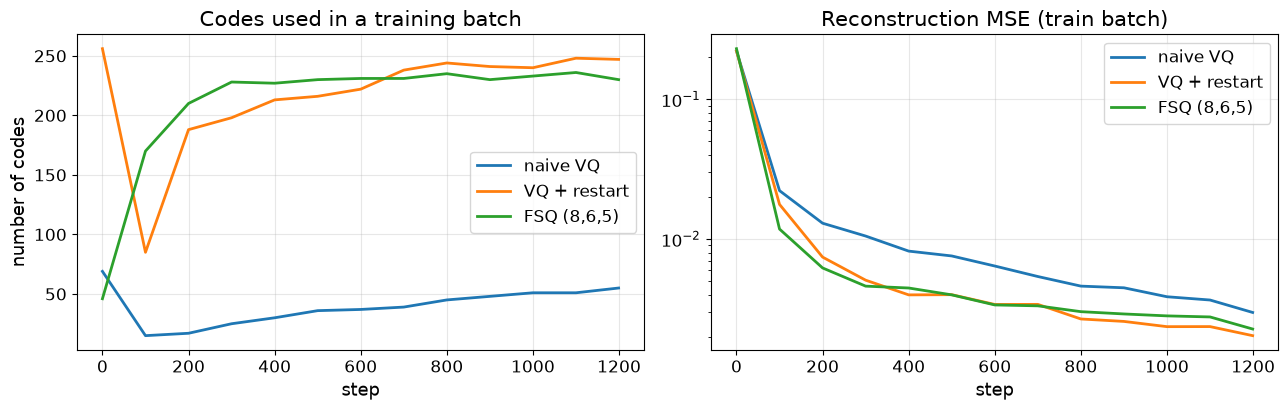

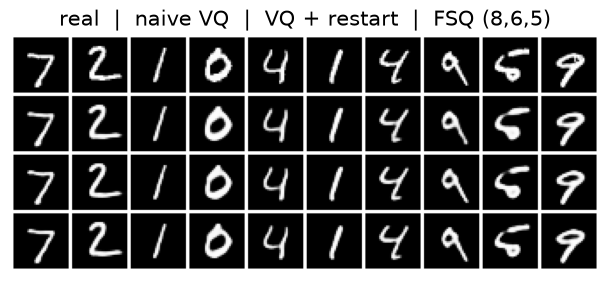

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for name, h in HIST.items():
    st = [r["step"] for r in h]
    ax[0].plot(st, [r["usage"] * 256 if "FSQ" not in name else r["usage"] * 240 for r in h], label=name, lw=2)
    ax[1].plot(st, [r["rec"] for r in h], label=name, lw=2)
ax[0].set_title("Codes used in a training batch", fontsize=15); ax[0].set_xlabel("step", fontsize=13); ax[0].set_ylabel("number of codes", fontsize=13)
ax[1].set_title("Reconstruction MSE (train batch)", fontsize=15); ax[1].set_xlabel("step", fontsize=13); ax[1].set_yscale("log")
for a in ax: a.legend(fontsize=12); a.grid(alpha=0.3); a.tick_params(labelsize=12)
plt.tight_layout(); plt.show()
x10 = Xte[:10]
show(torch.cat([x10] + [TOK[n].decode(TOK[n].encode(x10)).cpu() for n in cfgs]),
     title="real  |  naive VQ  |  VQ + restart  |  FSQ (8,6,5)")

Что видно. Наивный VQ показывает коллапс codebook: используется 24,6% кодов, перплексия 38 при $K = 256$. Механизм виден на левом графике: коды инициализированы около нуля, энкодер в начале обучения выдаёт векторы далеко от них, ближайшими оказываются немногие коды. Только они получают обновления и «уходят» к данным. За первые 100 шагов число используемых в батче кодов падает с 69 до 15 и дальше растёт очень медленно. Перезапуск мёртвых кодов возвращает их в область выходов энкодера: использование 99,6%, перплексия 182. FSQ без каких-либо вспомогательных потерь использует все 240 значений: у фиксированной решётки нет кодов, которые могли бы «умереть». По реконструкции разница скромнее, чем по использованию: PSNR 25,46 дБ у наивного VQ против 27,36 у VQ с перезапуском и 26,67 у FSQ, а rFD и точность классификатора на реконструкциях у всех трёх близки (7,7–9,2 и 0,91–0,92). Для MNIST примерно 40 «эффективных» кодов на позицию 4×4 уже хватает, чтобы сохранить цифру; на сложных данных и больших $K$ коллапс стоит заметно дороже (раздел 6).

## 17. Степень сжатия f и длина последовательности

### 17.1. Три токенизатора с f = 2, 4, 8

Обучим VQ с перезапуском ($K = 256$) при трёх степенях сжатия. Для изображения 32×32 это сетки 16×16, 8×8 и 4×4, то есть 256, 64 и 16 токенов. Модель с $f = 4$ уже обучена в разделе 16. Для каждой модели посчитаем:

- биты на изображение $N \log_2 K$ — сколько информации вообще может пройти через токенизатор;
- PSNR реконструкции;
- rFD — FD реконструкций тестовых изображений. Это нижняя граница FD для любого генератора поверх этого токенизатора: генератор не может нарисовать то, чего не умеет декодер;
- точность классификатора на реконструкциях — сохранилась ли «семантика» цифры.

f=2 trained in 81 s


f=8 trained in 65 s


/tmp/ipykernel_3714/3260384558.py:28: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = linalg.sqrtm(s1 @ s2)


 f   grid tokens bits/img  ratio   PSNR    rFD rec_acc  usage
 2  16x16    256     2048      4  31.80   5.18   0.919  1.000
 4    8x8     64      512     16  27.36   9.22   0.917  0.996
 8    4x4     16      128     64  22.60  35.66   0.878  0.992


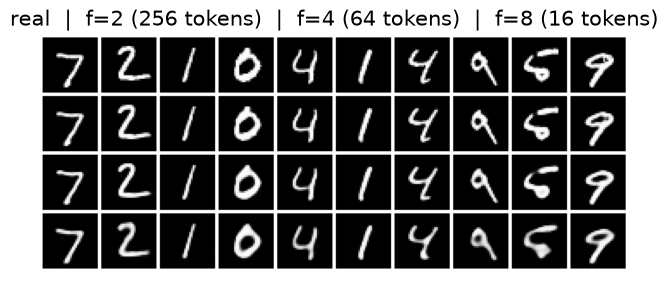

In [13]:
FTOK = {4: TOK["VQ + restart"]}
for f in [2, 8]:
    with Timer() as t: FTOK[f], _ = train_vqae(f, VQ(256, 16, init="data", restart=True), S["steps_f"])
    print(f"f={f} trained in {t.s:.0f} s")
rows = []
for f in [2, 4, 8]:
    r = eval_tokenizer(FTOK[f]); N = (32 // f) ** 2
    rows.append(dict(f=f, grid=f"{32 // f}x{32 // f}", tokens=N, bits=N * 8, **r))
print(f"{'f':>2} {'grid':>6} {'tokens':>6} {'bits/img':>8} {'ratio':>6} {'PSNR':>6} {'rFD':>6} {'rec_acc':>7} {'usage':>6}")
for r in rows:
    print(f"{r['f']:>2} {r['grid']:>6} {r['tokens']:>6} {r['bits']:>8} {32 * 32 * 8 / r['bits']:>6.0f} {r['psnr']:>6.2f} "
          f"{r['rFD']:>6.2f} {r['rec_acc']:>7.3f} {r['usage']:>6.3f}")
F_ROWS = rows
show(torch.cat([Xte[:10]] + [FTOK[f].decode(FTOK[f].encode(Xte[:10])).cpu() for f in [2, 4, 8]]),
     title="real  |  f=2 (256 tokens)  |  f=4 (64 tokens)  |  f=8 (16 tokens)")

Что видно. Колонка ratio — во сколько раз токены короче исходного изображения в битах (32×32 пикселя по 8 бит). При $f = 2$ реконструкция почти идеальна (PSNR 31,80 дБ, rFD 5,18), но последовательность длиной 256 — такая же, как у пиксельной модели в 16×16. При $f = 4$ — 64 токена, PSNR 27,36 дБ и rFD 9,22. При $f = 8$ последовательность короткая (16 токенов, 128 бит на изображение), но декодер вынужден «додумывать» штрихи: PSNR падает до 22,60 дБ, rFD растёт до 35,66, точность классификатора на реконструкциях снижается с 0,92 до 0,88. Это компромисс rate–distortion в чистом виде: длина последовательности для генератора против потолка качества реконструкции.

### 17.2. Сколько стоит длина последовательности

Сложность self-attention растёт как $N^2$, а авторегрессионная генерация требует $N$ последовательных проходов. Здесь же определим трансформер, который будет приором в разделах 20–23. Блок — pre-norm: внимание и MLP с остаточными связями. Внимание считается через `F.scaled_dot_product_attention`. Блок поддерживает KV-кэш: при генерации ключи и значения уже обработанных позиций сохраняются, и на каждом шаге через сеть проходит только новый токен. Без маски и без кэша внимание причинное (треугольная маска), с явной маской — любое (понадобится для VAR).

Замерим для батча из 16 последовательностей: время одного прямого прохода по всей последовательности и полное время генерации $N$ токенов с KV-кэшем (модель 4 слоя, $d = 192$, словарь 256).

In [14]:
class Block(nn.Module):
    def __init__(self, d, H, drop=0.1):
        super().__init__(); self.H, self.drop = H, drop
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.qkv, self.proj = nn.Linear(d, 3 * d), nn.Linear(d, d)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d), nn.Dropout(drop))
    def forward(self, x, mask=None, cache=None):
        B, T, C = x.shape
        q, k, v = self.qkv(self.ln1(x)).view(B, T, 3, self.H, C // self.H).permute(2, 0, 3, 1, 4)
        if cache is not None:                                   # KV-кэш: добавляем ключи и значения новых позиций
            if "k" in cache: k, v = torch.cat([cache["k"], k], 2), torch.cat([cache["v"], v], 2)
            cache["k"], cache["v"] = k, v
        causal = mask is None and cache is None
        a = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, is_causal=causal,
                                           dropout_p=self.drop if self.training else 0.0)
        x = x + self.proj(a.transpose(1, 2).reshape(B, T, C))
        return x + self.mlp(self.ln2(x))

class Transformer(nn.Module):
    def __init__(self, d, H, L):
        super().__init__(); self.blocks = nn.ModuleList([Block(d, H) for _ in range(L)]); self.ln = nn.LayerNorm(d)
    def new_cache(self): return [dict() for _ in self.blocks]
    def forward(self, x, mask=None, caches=None):
        for i, b in enumerate(self.blocks): x = b(x, mask, None if caches is None else caches[i])
        return self.ln(x)

probe = Transformer(192, 4, 4).to(DEVICE).eval(); emb = nn.Embedding(256, 192).to(DEVICE); head = nn.Linear(192, 256).to(DEVICE)
print(f"{'N':>5} {'forward ms':>10} {'x vs N=16':>9} {'gen steps':>9} {'generation s (KV cache)':>23}")
base = None
for N in [16, 64, 256, 1024]:
    x = torch.randn(16, N, 192, device=DEVICE)
    with torch.no_grad():
        probe(x)
        with Timer() as t:
            for _ in range(3): probe(x)
        caches = probe.new_cache(); h = x[:, :1]
        with Timer() as tg:
            for i in range(N):
                tok = head(probe(h, caches=caches))[:, -1].argmax(-1); h = emb(tok)[:, None]
    ms = t.s / 3 * 1000; base = base or ms
    print(f"{N:>5} {ms:>10.1f} {ms / base:>9.1f} {N:>9} {tg.s:>23.2f}")

    N forward ms x vs N=16 gen steps generation s (KV cache)
   16        5.0       1.0        16                    0.04


   64       16.8       3.4        64                    0.14


  256       85.8      17.1       256                    0.88


 1024      551.7     110.2      1024                    8.47


Что видно. При росте длины с 16 до 1024 (в 64 раза) прямой проход дорожает с 5,0 до 551,7 мс, то есть в 110 раз: сказывается квадратичная часть внимания. Генерация требует $N$ последовательных шагов. Даже с KV-кэшем, когда каждый шаг обрабатывает один токен, полное время генерации растёт сверхлинейно: каждый новый токен смотрит на все предыдущие. От 64 к 1024 токенам время генерации выросло с 0,14 до 8,47 с, примерно в 60 раз при 16-кратном росте длины. Ради этого и нужно пространственное сжатие: 256×256 пикселей с тремя каналами — это 196 608 символов, а при $f = 16$ — 256 токенов.

## 18. VQGAN-lite: перцептивная и adversarial-потери

При $f = 8$ реконструкции заметно размыты: попиксельная потеря наказывает за любую ошибку положения штриха, и декодеру выгоднее нарисовать «среднее». VQGAN ([Esser et al., 2021](https://arxiv.org/abs/2012.09841)) добавляет к попиксельной потере (у нас BCE, в VQGAN — L1/MSE) две потери:

- перцептивную — расстояние между признаками реального и восстановленного изображения в предобученной сети. В VQGAN это LPIPS на VGG; у нас роль сети признаков играет классификатор-оценщик, поэтому rFD этой модели немного «подыгрывает» (признаки те же), и судить надо также по картинкам;
- adversarial — патч-дискриминатор (PatchGAN) отличает реальные фрагменты от восстановленных; используем hinge-потерю.

Вес adversarial-потери выбирается адаптивно: $\lambda = \|\nabla_{G_L}\mathcal{L}_{\text{rec}}\| / (\|\nabla_{G_L}\mathcal{L}_{\text{GAN}}\| + \delta)$, где $G_L$ — последний слой декодера, $\delta = 10^{-6}$. Дискриминатор включается после 30% шагов: сначала декодер должен научиться хоть какой-то реконструкции, иначе дискриминатор выигрывает сразу.

trained: perceptual 183 s, VQGAN-lite 282 s; adaptive lambda: start 0.544, median 0.064, end 0.052


/tmp/ipykernel_3714/3260384558.py:28: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = linalg.sqrtm(s1 @ s2)


f=8 pixel BCE          PSNR=22.60  rFD=35.66  rec_acc=0.878  sharpness=0.90 x real  usage=0.992


f=8 BCE + perceptual   PSNR=22.90  rFD=15.14  rec_acc=0.910  sharpness=0.95 x real  usage=0.996


f=8 VQGAN-lite         PSNR=22.23  rFD=4.85  rec_acc=0.912  sharpness=0.99 x real  usage=0.996


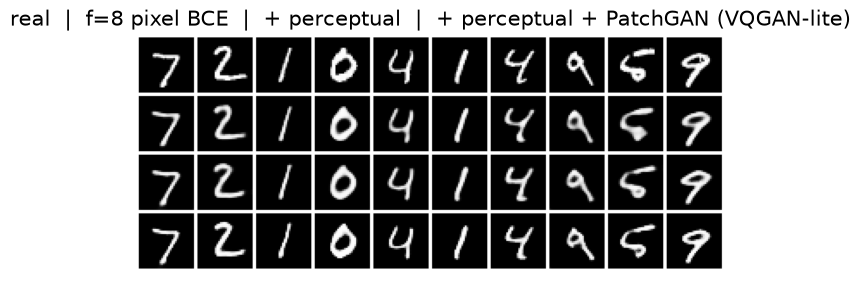

In [15]:
class PatchD(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(1, 32, 4, 2, 1), nn.LeakyReLU(0.2),
                                 nn.Conv2d(32, 64, 4, 2, 1), nn.GroupNorm(8, 64), nn.LeakyReLU(0.2),
                                 nn.Conv2d(64, 1, 3, 1, 1))                     # 8x8 логитов: по одному на патч
    def forward(self, x): return self.net(x)

PERC_LAYERS = [1, 4, 7]   # выходы ReLU в clf.f
def perc_feats(x):
    out, h = [], x
    for i, layer in enumerate(clf.f):
        h = layer(h)
        if i in PERC_LAYERS: out.append(h)
    return out
def perceptual(x, y):
    return sum(F.mse_loss(a / (a.pow(2).mean((1, 2, 3), keepdim=True).sqrt() + 1e-6),
                          b / (b.pow(2).mean((1, 2, 3), keepdim=True).sqrt() + 1e-6)) for a, b in zip(perc_feats(x), perc_feats(y)))

def train_vqgan(steps, use_gan=True, w_perc=1.0, w_disc=0.5, seed=0):
    seed_all(seed); m = VQAE(8, VQ(256, 16, init="data", restart=True)).to(DEVICE); D = PatchD().to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), 1e-3); optd = torch.optim.Adam(D.parameters(), 2e-4, betas=(0.5, 0.9))
    start = int(0.3 * steps); lams = []
    for step, (x, _) in enumerate(batches(Xtr, Ytr, S["bs"], steps, seed=20)):
        logits, idx, qloss = m(x); xr = logits.sigmoid()
        rec = F.binary_cross_entropy_with_logits(logits, x) + w_perc * perceptual(xr, x)
        loss = rec + qloss
        if use_gan and step >= start:
            g = -D(xr).mean()
            last = m.dec.out.weight
            gr = torch.autograd.grad(rec, last, retain_graph=True)[0].norm()
            gg = torch.autograd.grad(g, last, retain_graph=True)[0].norm()
            lam = (gr / (gg + 1e-6)).clamp(0, 1e4).detach(); lams.append(lam.item())
            loss = loss + w_disc * lam * g
        opt.zero_grad(); loss.backward(); opt.step()
        if use_gan and step >= start:
            d = F.relu(1 - D(x)).mean() + F.relu(1 + D(xr.detach())).mean()
            optd.zero_grad(); d.backward(); optd.step()
    return m.eval(), lams

def sharpness(x):
    k = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]]).view(1, 1, 3, 3)
    x = x.cpu().float(); gx, gy = F.conv2d(x, k, padding=1), F.conv2d(x, k.transpose(2, 3), padding=1)
    return (gx ** 2 + gy ** 2).sqrt().mean().item()

GAN = {"f=8 pixel BCE": FTOK[8]}
with Timer() as t1: GAN["f=8 BCE + perceptual"], _ = train_vqgan(S["steps_gan"], use_gan=False)
with Timer() as t2: GAN["f=8 VQGAN-lite"], LAMS = train_vqgan(S["steps_gan"], use_gan=True)
print(f"trained: perceptual {t1.s:.0f} s, VQGAN-lite {t2.s:.0f} s; adaptive lambda: start {LAMS[0]:.3f}, "
      f"median {np.median(LAMS):.3f}, end {LAMS[-1]:.3f}")
sh_real = sharpness(Xte[:2000])
for name, m in GAN.items():
    r = eval_tokenizer(m); rec = m.decode(m.encode(Xte[:2000])).cpu()
    print(f"{name:22s} PSNR={r['psnr']:.2f}  rFD={r['rFD']:.2f}  rec_acc={r['rec_acc']:.3f}  "
          f"sharpness={sharpness(rec) / sh_real:.2f} x real  usage={r['usage']:.3f}")
show(torch.cat([Xte[:10]] + [m.decode(m.encode(Xte[:10])).cpu() for m in GAN.values()]),
     title="real  |  f=8 pixel BCE  |  + perceptual  |  + perceptual + PatchGAN (VQGAN-lite)")

Что видно. Перцептивная и adversarial-потери меняют то, что оптимизирует токенизатор. PSNR почти не меняется: 22,60 дБ у чисто попиксельной потери, 22,90 с перцептивной, 22,23 у VQGAN-lite. Зато rFD падает с 35,66 до 15,14 и затем до 4,85, точность классификатора на реконструкциях растёт с 0,878 до 0,910–0,912, а резкость (средняя величина градиента яркости относительно реальных изображений) — с 0,90 до 0,95 и 0,99. Падение rFD частично завышено: перцептивная потеря использует признаки того же классификатора, что и FD. Для генерации важнее семантика и резкость: генератор поверх токенизатора унаследует «стиль» реконструкции. Адаптивный $\lambda$ уравнивает вклад двух градиентов на последнем слое декодера. Его значение за обучение изменилось с 0,544 в момент включения дискриминатора до 0,052 в конце (медиана 0,064), поэтому фиксированный вес подобрать трудно. На картинках эффект скромный: у цифр мало текстуры, а именно текстуру попиксельная потеря размывает сильнее всего.

## 19. Предобученный токенизатор: латент Stable Diffusion

Наши токенизаторы обучены на цифрах. Посмотрим, как устроен латент настоящего генератора. TAESD ([madebyollin/taesd](https://huggingface.co/madebyollin/taesd)) — маленький (2,4 млн параметров) дистиллированный автоэнкодер, совместимый с латентным пространством VAE Stable Diffusion: $f = 8$, 4 канала. Сам VAE Stable Diffusion — KL-регуляризованный непрерывный автоэнкодер из работы о латентной диффузии, где $f$ от 4 до 16 названы хорошим компромиссом между сжатием и качеством ([Rombach et al., 2022](https://arxiv.org/abs/2112.10752)). Латент непрерывный: для авторегрессии по токенам его пришлось бы квантовать, а диффузия работает с ним напрямую.

/home/user/cvtest/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/user/cvtest/.venv/lib/python3.12/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


TAESD params: 2445063 | image (640, 480)


512x512: latent (4, 64, 64) = 16384 numbers vs 786432 input values (48x fewer), latent positions = 4096, PSNR=23.29 dB


256x256: latent (4, 32, 32) = 4096 numbers vs 196608 input values (48x fewer), latent positions = 1024, PSNR=21.58 dB
128x128: latent (4, 16, 16) = 1024 numbers vs 49152 input values (48x fewer), latent positions = 256, PSNR=19.19 dB


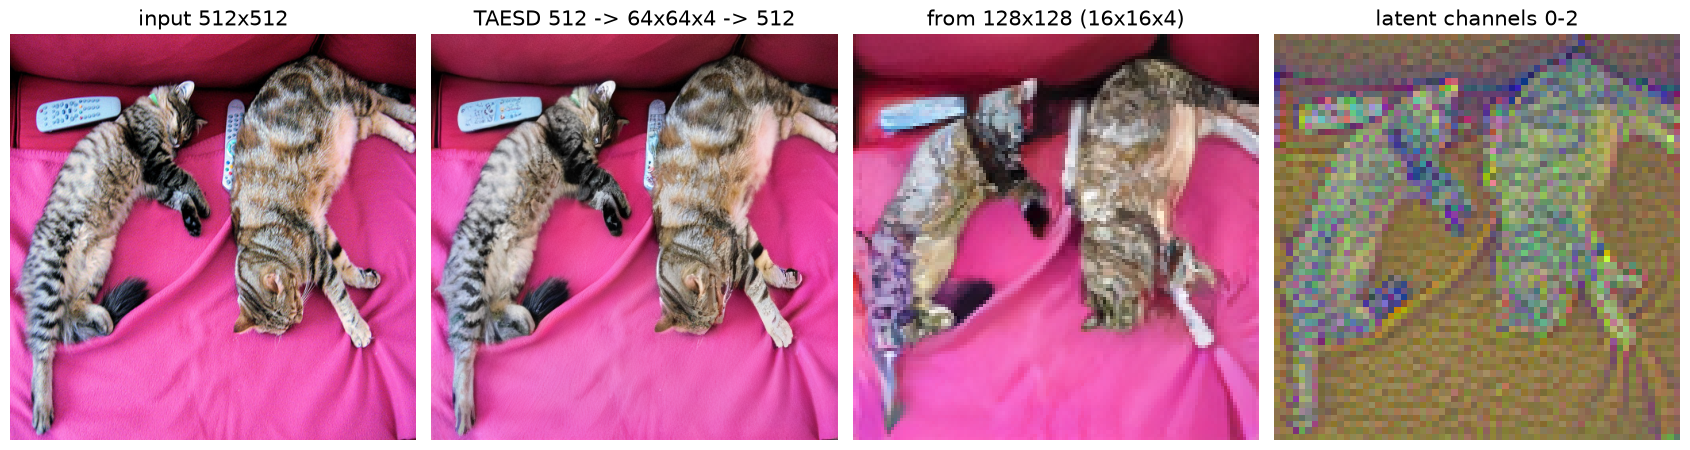

In [16]:
from diffusers import AutoencoderTiny
from PIL import Image
taesd = AutoencoderTiny.from_pretrained("madebyollin/taesd").to(DEVICE).eval()
url = "http://images.cocodataset.org/val2017/000000039769.jpg"     # две кошки на диване, COCO val2017
img = Image.open(io.BytesIO(urllib.request.urlopen(url, timeout=30).read())).convert("RGB")
print("TAESD params:", n_params(taesd), "| image", img.size)
rows = []
for side in [512, 256, 128]:
    x = torchvision.transforms.functional.to_tensor(img.resize((side, side), Image.BICUBIC))[None].to(DEVICE)
    with torch.no_grad():
        lat = taesd.encode(x * 2 - 1).latents; rec = (taesd.decode(lat).sample.clamp(-1, 1) + 1) / 2
    rows.append((side, tuple(lat.shape[1:]), x.cpu(), rec.cpu(), lat.cpu()))
    n_in, n_lat = x.numel(), lat.numel()
    print(f"{side}x{side}: latent {tuple(lat.shape[1:])} = {n_lat} numbers vs {n_in} input values "
          f"({n_in / n_lat:.0f}x fewer), latent positions = {lat.shape[2] * lat.shape[3]}, PSNR={psnr(rec.cpu(), x.cpu()):.2f} dB")
fig, ax = plt.subplots(1, 4, figsize=(17, 4.6))
ax[0].imshow(rows[0][2][0].permute(1, 2, 0)); ax[0].set_title("input 512x512", fontsize=15)
ax[1].imshow(rows[0][3][0].permute(1, 2, 0)); ax[1].set_title("TAESD 512 -> 64x64x4 -> 512", fontsize=15)
ax[2].imshow(rows[2][3][0].permute(1, 2, 0)); ax[2].set_title("from 128x128 (16x16x4)", fontsize=15)
lat = rows[0][4][0]; ax[3].imshow(lat[:3].permute(1, 2, 0).sub(lat.min()).div(lat.max() - lat.min())); ax[3].set_title("latent channels 0-2", fontsize=15)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

Что видно. Латент 64×64×4 в 48 раз меньше входа по числу значений. Реконструкция с 512×512 на глаз близка к оригиналу, хотя PSNR всего 23,29 дБ: ошибки сосредоточены в мелкой текстуре шерсти и ткани, а PSNR чувствителен именно к ним. Автор позиционирует TAESD как более быстрый вариант ценой немного сниженного качества ([madebyollin/taesd](https://huggingface.co/madebyollin/taesd)), поэтому у полного VAE Stable Diffusion реконструкция должна быть точнее. Сам латент выглядит как уменьшенная «раскрашенная» копия изображения: сжатие перцептивное, а не семантическое, и пространственная структура сохраняется. При входе 128×128 латент — всего 16×16 позиций, PSNR падает до 19,19 дБ, а мелкие детали (морды кошек, кнопки пультов) превращаются в пятна: число позиций, а не только $f$, ограничивает детализацию. Для авторегрессии по токенам 64×64 = 4096 позиций — это длинная последовательность, поэтому авторегрессионные генераторы обычно используют $f = 16$ (256 токенов на 256×256).

### 19.1. Длина последовательности в современных токенизаторах

Таблица ниже пересчитывает опубликованные параметры в число визуальных токенов и в биты на изображение. Источники параметров указаны в теоретическом разделе 9.

In [17]:
tokenizers = [  # name, image side, spatial factor f (pixels per token side), codebook K (None = continuous), note
    ("VQ-VAE (ImageNet 128)", 128, 4, 512, "discrete, PixelCNN prior"),
    ("DALL-E dVAE", 256, 8, 8192, "discrete, AR transformer"),
    ("VQGAN f=16", 256, 16, 16384, "discrete, AR transformer"),
    ("ViT-VQGAN", 256, 8, 8192, "discrete, AR transformer"),
    ("MaskGIT", 256, 16, 1024, "discrete, masked parallel decoding"),
    ("LlamaGen f=16", 256, 16, 16384, "discrete, AR (Llama)"),
    ("Chameleon", 512, 16, 8192, "discrete, mixed-modal LLM"),
    ("Emu3", 512, 8, 32768, "discrete, next-token LLM"),
    ("Janus (generation)", 384, 16, 16384, "discrete, LLM generation path"),
    ("SD VAE / TAESD", 512, 8, None, "continuous 4 ch, diffusion"),
    ("Janus (understanding, SigLIP-L/16)", 384, 16, None, "continuous, VLM input"),
    ("Qwen2-VL 224 (understanding)", 224, 28, None, "patch 14 + 2x2 merge"),
]
print(f"{'tokenizer':36s} {'image':>5} {'f':>3} {'grid':>7} {'tokens':>6} {'K':>6} {'bits/token':>10} {'bits/img':>8}  note")
for name, side, f, K, note in tokenizers:
    g = side // f; n = g * g
    b = f"{math.log2(K):.0f}" if K else "-"; bi = f"{n * math.log2(K):.0f}" if K else "-"
    print(f"{name:36s} {side:>5} {f:>3} {f'{g}x{g}':>7} {n:>6} {K or '-':>6} {b:>10} {bi:>8}  {note}")

tokenizer                            image   f    grid tokens      K bits/token bits/img  note
VQ-VAE (ImageNet 128)                  128   4   32x32   1024    512          9     9216  discrete, PixelCNN prior
DALL-E dVAE                            256   8   32x32   1024   8192         13    13312  discrete, AR transformer
VQGAN f=16                             256  16   16x16    256  16384         14     3584  discrete, AR transformer
ViT-VQGAN                              256   8   32x32   1024   8192         13    13312  discrete, AR transformer
MaskGIT                                256  16   16x16    256   1024         10     2560  discrete, masked parallel decoding
LlamaGen f=16                          256  16   16x16    256  16384         14     3584  discrete, AR (Llama)
Chameleon                              512  16   32x32   1024   8192         13    13312  discrete, mixed-modal LLM
Emu3                                   512   8   64x64   4096  32768         15    61440  dis

Что видно. Генеративные токенизаторы сходятся к 256–1024 токенам на изображение (Emu3 с 4096 — исключение) — это длины, на которых авторегрессионный трансформер ещё можно обучить и сэмплировать. Один дискретный токен несёт 9–15 бит. Изображение 256×256 при $f = 16$ описывается 2,6–3,6 тыс. бит, то есть менее чем 0,5 КБ: в десятки раз меньше типичного JPEG того же размера. Поэтому декодер обязан «дорисовывать» детали. Токенизаторы для понимания (SigLIP в Janus, ViT в Qwen2-VL) непрерывные: им не нужно ничего генерировать, а квантование только потеряло бы информацию. Для Qwen2-VL расчёт даёт 64 токена; в статье указано 66, потому что добавляются служебные `<|vision_start|>` и `<|vision_end|>`.

## 20. Пиксельный авторегрессор: ImageGPT в миниатюре

### 20.1. Трансформер-декодер и функции сэмплинга

Трансформер из раздела 17.2 (causal self-attention, pre-norm, KV-кэш) с обучаемыми позиционными эмбеддингами будет приором и для пикселей, и для кодов VQ. Первый токен входа — эмбеддинг класса: для безусловной модели класс один и работает как токен начала последовательности. Модель предсказывает токен $t$ по всем предыдущим; обучение — teacher forcing, потеря — кросс-энтропия, как в языковой модели.

Функция `filter_logits` реализует три ручки сэмплинга из раздела 11: temperature делит логиты, top-k оставляет $k$ самых вероятных токенов, top-p оставляет наименьший набор токенов с суммарной вероятностью не меньше $p$ ([Holtzman et al., 2019](https://arxiv.org/abs/1904.09751)). Температура 0 означает жадный выбор (argmax).

In [18]:
class GPT(nn.Module):
    def __init__(self, vocab, seq_len, n_cls, d=192, L=4, H=4):
        super().__init__()
        self.tok, self.cls = nn.Embedding(vocab, d), nn.Embedding(n_cls, d)
        self.pos = nn.Parameter(torch.randn(1, seq_len, d) * 0.02)
        self.tf, self.head = Transformer(d, H, L), nn.Linear(d, vocab)
    def forward(self, c, prefix):                    # prefix: B x T токенов -> логиты для позиций 0..T
        h = torch.cat([self.cls(c)[:, None], self.tok(prefix)], 1)
        return self.head(self.tf(h + self.pos[:, :h.shape[1]]))
    @torch.no_grad()
    def generate(self, c, N, **kw):                  # растровая генерация с KV-кэшем: N проходов по одному токену
        caches = self.tf.new_cache(); h = self.cls(c)[:, None] + self.pos[:, :1]; out = []
        for t in range(N):
            nxt = sample_tokens(self.head(self.tf(h, caches=caches))[:, -1], **kw); out.append(nxt)
            if t + 1 < N: h = self.tok(nxt)[:, None] + self.pos[:, t + 1:t + 2]
        return torch.stack(out, 1)

def filter_logits(logits, temperature=1.0, top_k=0, top_p=1.0):
    logits = logits / temperature
    if top_k and top_k < logits.shape[-1]:
        kth = torch.topk(logits, top_k).values[..., -1:]
        logits = logits.masked_fill(logits < kth, float("-inf"))
    if top_p < 1.0:
        sl, si = logits.sort(-1, descending=True); p = sl.softmax(-1)
        remove = (p.cumsum(-1) - p) >= top_p          # масса до токена уже >= p: токен лишний
        logits = torch.full_like(logits, float("-inf")).scatter(-1, si, sl.masked_fill(remove, float("-inf")))
    return logits

def sample_tokens(logits, temperature=1.0, top_k=0, top_p=1.0):
    if temperature == 0: return logits.argmax(-1)
    shape = logits.shape[:-1]; lg = filter_logits(logits.reshape(-1, logits.shape[-1]), temperature, top_k, top_p)
    return torch.multinomial(lg.softmax(-1), 1).view(shape)

def generate_ar(model, c, N, bs=250, **kw):
    return torch.cat([model.generate(c[i:i + bs].to(DEVICE), N, **kw) for i in range(0, len(c), bs)])

def train_gpt(model, seqs, labels, steps, bs=64, lr=1e-3, seed=0):
    seed_all(seed); opt = torch.optim.AdamW(model.parameters(), lr, weight_decay=0.01)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=steps, pct_start=0.05)
    hist = []; model.train()
    for step, (s, c) in enumerate(batches(seqs, labels, bs, steps, seed=seed + 30)):
        loss = F.cross_entropy(model(c, s[:, :-1]).flatten(0, 1), s.flatten())
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
        if step % 100 == 0 or step == steps - 1: hist.append((step, loss.item()))
    return model.eval(), hist

# Проверка KV-кэша: пошаговые логиты с кэшем совпадают с логитами полного прохода по той же последовательности
g_test = GPT(16, 12, 2, d=64, L=2, H=4).to(DEVICE).eval(); c_t = torch.tensor([0, 1], device=DEVICE)
with torch.no_grad():
    seq_t = torch.randint(0, 16, (2, 11), device=DEVICE); full = g_test(c_t, seq_t)              # 2 x 12 x 16
    caches = g_test.tf.new_cache(); h = g_test.cls(c_t)[:, None] + g_test.pos[:, :1]; steps = []
    for t in range(12):
        steps.append(g_test.head(g_test.tf(h, caches=caches))[:, -1])
        if t < 11: h = g_test.tok(seq_t[:, t])[:, None] + g_test.pos[:, t + 1:t + 2]
print("KV-cache logits == full forward logits:", torch.allclose(torch.stack(steps, 1), full, atol=1e-5))

# Как работают фильтры: два распределения из 8 токенов, «уверенное» и «плоское»
toy = torch.log(torch.tensor([[0.80, 0.08, 0.04, 0.03, 0.02, 0.01, 0.01, 0.01],
                              [0.16, 0.15, 0.14, 0.13, 0.12, 0.11, 0.10, 0.09]]))
for name, kw in [("top-k=3", dict(top_k=3)), ("top-p=0.9", dict(top_p=0.9)), ("T=0.5", dict(temperature=0.5)), ("T=2.0", dict(temperature=2.0))]:
    p = filter_logits(toy.clone(), **kw).softmax(-1)
    print(f"{name:9s} peaked: kept {int((p[0] > 0).sum())} tokens, p(top)={p[0, 0]:.2f} | "
          f"flat: kept {int((p[1] > 0).sum())} tokens, p(top)={p[1, 0]:.2f}")

KV-cache logits == full forward logits: True
top-k=3   peaked: kept 3 tokens, p(top)=0.87 | flat: kept 3 tokens, p(top)=0.36
top-p=0.9 peaked: kept 3 tokens, p(top)=0.87 | flat: kept 7 tokens, p(top)=0.18
T=0.5     peaked: kept 8 tokens, p(top)=0.99 | flat: kept 8 tokens, p(top)=0.20
T=2.0     peaked: kept 8 tokens, p(top)=0.45 | flat: kept 8 tokens, p(top)=0.14


Что видно. Top-k оставляет 3 токена в обоих случаях: для «уверенного» распределения это лишние кандидаты, для «плоского» — отсечение правдоподобных вариантов. Top-p адаптивен: для «уверенного» распределения оставляет 3 токена (0,80 + 0,08 + 0,04 ≥ 0,9), для «плоского» — 7 из 8. Температура не отсекает токены, а меняет форму распределения: при $T = 0{,}5$ вероятность лидера растёт, при $T = 2$ распределение выравнивается.

### 20.2. Обучение на пикселях в палитре

Модель на 256 символах из раздела 14 (палитра из 8 уровней, 16×16), без условия на класс. На CPU $d = 96$, 3 слоя; на GPU $d = 128$, 4 слоя. Метрика — bits/dim на тесте: теперь это точное правдоподобие, и его можно поставить в один ряд с моделями раздела 14.

pixel AR: 0.36M params, trained 1066 s
test bits/dim: uniform 3.000 | independent pixels 0.844 | pixel AR 0.669


/tmp/ipykernel_3714/3260384558.py:28: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = linalg.sqrtm(s1 @ s2)


generation: 200 samples x 256 steps in 2.8 s
real test after 16x16 palette round-trip: FD=25.06  conf=0.897  div=0.925
pixel AR samples:                         FD=204.03  conf=0.773  div=1.239  time_s=2.820


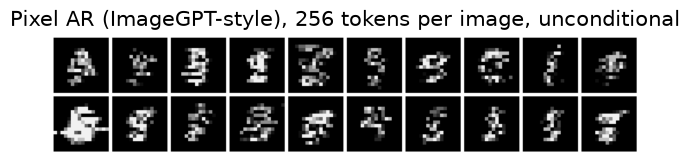

In [19]:
seed_all(0)
pix_model = GPT(PAL_K, 256, 1, d=S["d_pix"], L=S["L_pix"], H=4).to(DEVICE)
with Timer() as t: pix_model, pix_hist = train_gpt(pix_model, Ptr, torch.zeros(len(Ptr), dtype=torch.long), S["steps_pix"], bs=S["bs_pix"])
with torch.no_grad():
    nll = [F.cross_entropy(pix_model(torch.zeros(500, dtype=torch.long, device=DEVICE), Pte[i:i + 500, :-1].to(DEVICE)).flatten(0, 1),
                           Pte[i:i + 500].flatten().to(DEVICE)).item() for i in range(0, 2000, 500)]
BPD_PIX = float(np.mean(nll)) / LN2
print(f"pixel AR: {n_params(pix_model) / 1e6:.2f}M params, trained {t.s:.0f} s")
print(f"test bits/dim: uniform {math.log2(PAL_K):.3f} | independent pixels {bpd_indep:.3f} | pixel AR {BPD_PIX:.3f}")
seed_all(1)
with Timer() as tg: pix_seq = generate_ar(pix_model, torch.zeros(S["n_eval"], dtype=torch.long), 256)
pix_imgs = F.interpolate(from_pal(pix_seq), size=32, mode="nearest")
floor_pix = evaluate(F.interpolate(from_pal(Pte[REF_IDX]), size=32, mode="nearest"))
PIX_EVAL = evaluate(pix_imgs); PIX_EVAL["time_s"] = tg.s
print(f"generation: {S['n_eval']} samples x 256 steps in {tg.s:.1f} s")
print("real test after 16x16 palette round-trip:", fmt(floor_pix))
print("pixel AR samples:                        ", fmt(PIX_EVAL))
show(pix_imgs[:20], title="Pixel AR (ImageGPT-style), 256 tokens per image, unconditional")

Что видно. Авторегрессионная модель снижает bits/dim с 0,844 у модели независимых пикселей до 0,669: она использует зависимость пикселя от уже нарисованных. Но образцы в этом CPU-прогоне в основном не похожи на цифры: FD = 204 (хуже, чем у VAE), уверенность классификатора 0,773, разнообразие 1,24 — больше, чем у реальных данных, то есть модель рассеивает массу по «нецифрам». Это вторая иллюстрация того, что правдоподобие и качество образцов — разные вещи: модель из 0,36 млн параметров после 800 шагов уже хорошо предсказывает фон и края, но не глобальную форму. Строка «real test after palette round-trip» (FD = 25,06) — потолок для этой модели: даже идеальный приор на 16×16 с палитрой не даст FD ниже. Цена — 256 последовательных проходов трансформера на изображение (2,8 с на 200 образцов), и это всего 16×16 пикселей в оттенках серого. ImageGPT на 64×64 в цвете — это 4096 шагов.

## 21. Трансформер по кодам VQ: VQGAN-Transformer в миниатюре

Теперь двухэтапная схема из VQ-VAE и VQGAN: токенизатор (VQ с перезапуском, $f = 4$, 64 токена из словаря 256) заморожен, трансформер обучается предсказывать коды в растровом порядке. Условие — класс цифры в первом токене. Обучающие последовательности получаем, один раз пропустив все 60 000 изображений через энкодер.

encoded train+test in 19 s: codes (60000, 64), vocabulary 256


code AR: 0.87M params, trained 351 s; test 4.213 bits/token = 270 bits/image (vs 171 bits/image for pixel AR on 16x16 palette)


/tmp/ipykernel_3714/3260384558.py:28: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = linalg.sqrtm(s1 @ s2)


generation: 200 samples x 64 steps in 0.6 s
tokenizer reconstructions (floor): FD=7.40  conf=0.919  div=0.987  acc=0.920
code AR samples, T=1:              FD=12.07  conf=0.829  div=1.089  acc=0.715  time_s=0.572


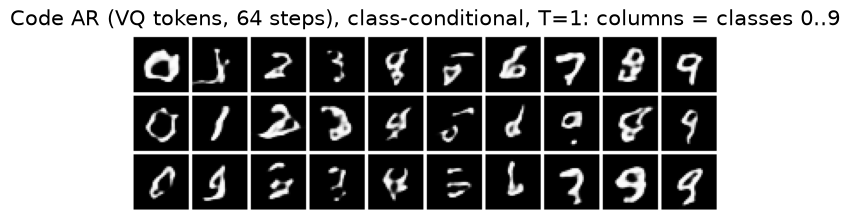

In [20]:
TK = TOK["VQ + restart"]
with Timer() as t:
    Ctr = torch.cat([TK.encode(Xtr[i:i + 1000]).flatten(1).cpu() for i in range(0, len(Xtr), 1000)])
    Cte = torch.cat([TK.encode(Xte[i:i + 1000]).flatten(1).cpu() for i in range(0, len(Xte), 1000)])
print(f"encoded train+test in {t.s:.0f} s: codes {tuple(Ctr.shape)}, vocabulary {TK.q.K}")
seed_all(0)
ar_model = GPT(TK.q.K, 64, 10, d=S["d_ar"], L=4, H=4).to(DEVICE)
with Timer() as t: ar_model, ar_hist = train_gpt(ar_model, Ctr, Ytr, S["steps_ar"], bs=S["bs"])
with torch.no_grad():
    nll = [F.cross_entropy(ar_model(Yte[i:i + 500].to(DEVICE), Cte[i:i + 500, :-1].to(DEVICE)).flatten(0, 1),
                           Cte[i:i + 500].flatten().to(DEVICE)).item() for i in range(0, 2000, 500)]
ar_bits = float(np.mean(nll)) / LN2
print(f"code AR: {n_params(ar_model) / 1e6:.2f}M params, trained {t.s:.0f} s; test {ar_bits:.3f} bits/token "
      f"= {64 * ar_bits:.0f} bits/image (vs {256 * BPD_PIX:.0f} bits/image for pixel AR on 16x16 palette)")
EVAL_LABELS = torch.arange(10).repeat_interleave(S["n_eval"] // 10)
def gen_codes(**kw):
    seed_all(1)
    with Timer() as t: seq = generate_ar(ar_model, EVAL_LABELS, 64, **kw)
    imgs = torch.cat([TK.decode(seq[i:i + 500].view(-1, 8, 8)).cpu() for i in range(0, len(seq), 500)])
    return imgs, t.s
ar_imgs, ar_t = gen_codes(temperature=1.0)
AR_EVAL = evaluate(ar_imgs, EVAL_LABELS); AR_EVAL["time_s"] = ar_t
print(f"generation: {S['n_eval']} samples x 64 steps in {ar_t:.1f} s")
print("tokenizer reconstructions (floor):", fmt(evaluate(TK.decode(Cte[REF_IDX].view(-1, 8, 8)).cpu(), Yte[REF_IDX])))
print("code AR samples, T=1:             ", fmt(AR_EVAL))
k = S["n_eval"] // 10
show(torch.cat([ar_imgs[c * k:c * k + 3] for c in range(10)]).view(10, 3, 1, 32, 32).transpose(0, 1).reshape(30, 1, 32, 32),
     title="Code AR (VQ tokens, 64 steps), class-conditional, T=1: columns = classes 0..9")

Что видно. Трансформер по кодам тратит на изображение 64 шага вместо 256, а каждый шаг выбирает один из 256 «кусков» 4×4 пикселя, а не один пиксель. Колонка bits/image (270 бит против 171 у пиксельной модели) не сравнима напрямую: токенизатор с потерями уже выбросил часть информации, модель описывает не изображение, а его код, и словари разные. Строка «tokenizer reconstructions» (FD = 7,40) — потолок качества: FD образцов не может стать заметно ниже FD реконструкций. Образцы при $T = 1$ дают FD = 12,07 — в 17 раз лучше пиксельной модели при вчетверо меньшем числе шагов: токенизатор взял на себя локальные детали. Условие на класс работает лишь частично: точность класса 0,715 против 0,920 на реконструкциях, разнообразие 1,09 больше, чем у данных, а на картинке часть образцов — кривые или «рваные» цифры. Модель мала и недообучена, и при $T = 1$ хвост её распределения даёт мусорные токены; в разделе 22 это лечится настройками сэмплинга.

## 22. Temperature, top-k, top-p: компромисс качество–разнообразие

Одна и та же обученная модель, разные правила выбора токена. Для каждой настройки генерируем ту же выборку (по 20 изображений каждого класса на CPU, по 100 на GPU) с одинаковым сидом и считаем FD, точность класса и разнообразие.

In [21]:
SWEEP = [("greedy (T=0)", dict(temperature=0)),
         ("T=0.5", dict(temperature=0.5)), ("T=0.8", dict(temperature=0.8)),
         ("T=1.0", dict(temperature=1.0)), ("T=1.3", dict(temperature=1.3)),
         ("top-k=5", dict(top_k=5)), ("top-k=50", dict(top_k=50)),
         ("top-p=0.8", dict(top_p=0.8)), ("top-p=0.95", dict(top_p=0.95)),
         ("T=1.3, top-p=0.9", dict(temperature=1.3, top_p=0.9))]
SW = {}
for name, kw in SWEEP:
    imgs, ts = gen_codes(**kw); r = evaluate(imgs, EVAL_LABELS); r["time_s"] = ts; SW[name] = (r, imgs)
    n_unique = len({tuple(v) for v in (imgs.view(len(imgs), -1) * 255).round().int().tolist()})
    print(f"{name:18s} {fmt(r)}  unique images {n_unique}/{len(imgs)}")

/tmp/ipykernel_3714/3260384558.py:28: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = linalg.sqrtm(s1 @ s2)


greedy (T=0)       FD=24.41  conf=0.993  div=0.000  acc=1.000  time_s=0.457  unique images 10/200


T=0.5              FD=6.84  conf=0.899  div=0.833  acc=0.820  time_s=0.597  unique images 200/200


T=0.8              FD=10.04  conf=0.848  div=0.977  acc=0.765  time_s=0.553  unique images 200/200


T=1.0              FD=12.07  conf=0.829  div=1.089  acc=0.715  time_s=0.581  unique images 200/200


...

top-k=5            FD=11.40  conf=0.912  div=0.800  acc=0.855  time_s=0.546  unique images 200/200


top-k=50           FD=9.52  conf=0.841  div=1.012  acc=0.750  time_s=0.711  unique images 200/200


top-p=0.8          FD=8.77  conf=0.867  div=0.874  acc=0.815  time_s=0.683  unique images 200/200


top-p=0.95         FD=8.01  conf=0.850  div=0.950  acc=0.760  time_s=0.703  unique images 200/200


T=1.3, top-p=0.9   FD=19.80  conf=0.822  div=1.050  acc=0.715  time_s=0.691  unique images 200/200


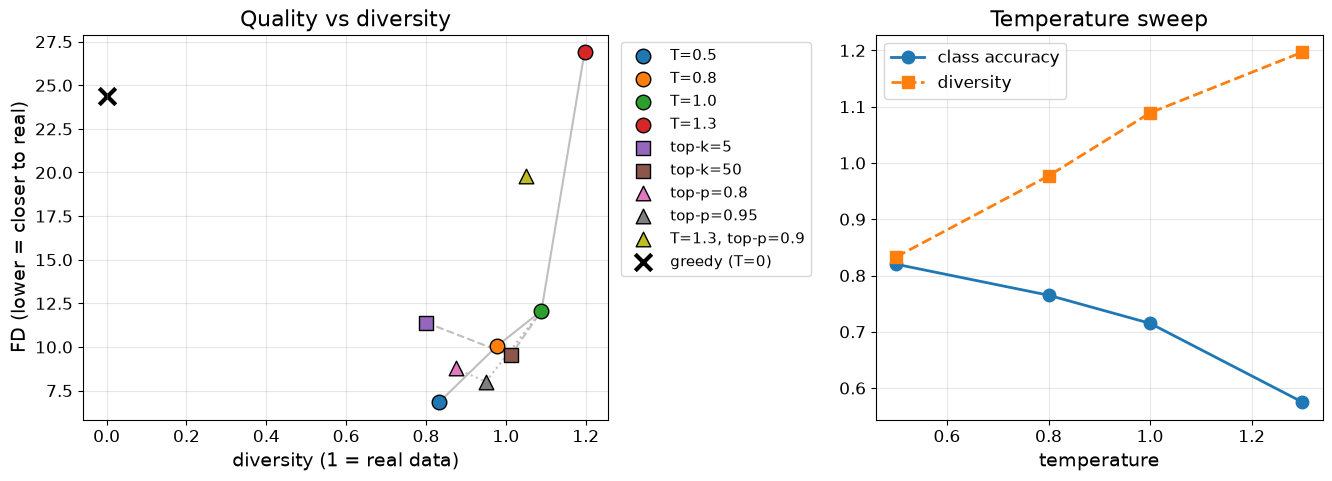

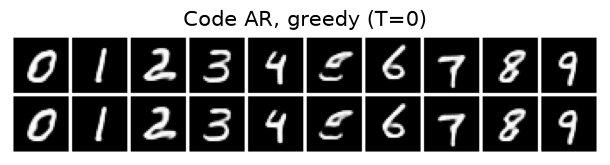

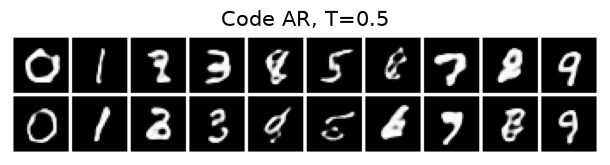

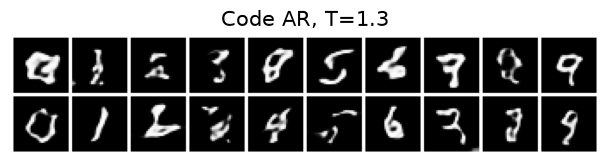

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw=dict(width_ratios=[1, 0.85], wspace=0.55))
groups = {"temperature": ["T=0.5", "T=0.8", "T=1.0", "T=1.3"], "top-k": ["top-k=5", "top-k=50", "T=1.0"],
          "top-p": ["top-p=0.8", "top-p=0.95", "T=1.0"]}
for (gname, names), mk in zip(groups.items(), ["o-", "s--", "^:"]):
    ax[0].plot([SW[n][0]["div"] for n in names], [SW[n][0]["FD"] for n in names], mk[1:], color="0.75", lw=1.5, zorder=1)
for i, (name, _) in enumerate(SWEEP[1:]):
    mk = "o" if name.startswith("T=") and "top" not in name else "s" if "top-k" in name else "^"
    ax[0].scatter(SW[name][0]["div"], SW[name][0]["FD"], marker=mk, s=110, color=plt.cm.tab10(i), edgecolor="k", zorder=3, label=name)
ax[0].scatter(SW["greedy (T=0)"][0]["div"], SW["greedy (T=0)"][0]["FD"], marker="x", s=140, color="k", linewidths=3, label="greedy (T=0)")
ax[0].set_xlabel("diversity (1 = real data)", fontsize=14); ax[0].set_ylabel("FD (lower = closer to real)", fontsize=14)
ax[0].set_title("Quality vs diversity", fontsize=16); ax[0].legend(fontsize=11, loc="upper left", bbox_to_anchor=(1.01, 1)); ax[0].grid(alpha=0.3); ax[0].tick_params(labelsize=12)
ts = ["T=0.5", "T=0.8", "T=1.0", "T=1.3"]
ax[1].plot([0.5, 0.8, 1.0, 1.3], [SW[n][0]["acc"] for n in ts], "o-", lw=2, ms=9, label="class accuracy")
ax[1].plot([0.5, 0.8, 1.0, 1.3], [SW[n][0]["div"] for n in ts], "s--", lw=2, ms=9, label="diversity")
ax[1].set_xlabel("temperature", fontsize=14); ax[1].set_title("Temperature sweep", fontsize=16)
ax[1].legend(fontsize=12); ax[1].grid(alpha=0.3); ax[1].tick_params(labelsize=12)
plt.show()
k = S["n_eval"] // 10
for name in ["greedy (T=0)", "T=0.5", "T=1.3"]:
    imgs = SW[name][1]
    show(torch.cat([imgs[c * k:c * k + 2] for c in range(10)]).view(10, 2, 1, 32, 32).transpose(0, 1).reshape(20, 1, 32, 32),
         title=f"Code AR, {name}")

Что видно. Жадный выбор даёт одно изображение на класс (10 уникальных из 200): точность класса 1,000, но разнообразие 0 и FD = 24,41, потому что вся масса распределения сосредоточена в 10 точках. Понижение температуры повышает уверенность и точность класса и снижает разнообразие: от $T = 1{,}3$ к $T = 0{,}5$ точность растёт с 0,575 до 0,820, разнообразие падает с 1,20 до 0,83. Повышение температуры добавляет «рваные» штрихи из хвоста распределения: при $T = 1{,}3$ FD = 26,90. Top-p 0,9 поверх $T = 1{,}3$ отсекает часть хвоста и снижает FD до 19,80 при разнообразии 1,05. В этом прогоне лучший FD дала $T = 0{,}5$ (6,84), затем top-p 0,95 (8,01) и top-p 0,8 (8,77); $T = 1$ без отсечений даёт 12,07. Причина — недообученная модель с завышенным разнообразием (1,09 при $T = 1$): умеренное сужение распределения убирает мусор быстрее, чем теряет покрытие. У хорошо обученных моделей оптимум обычно ближе к $T = 1$ с мягким отсечением, как в LlamaGen (раздел 11.5). Top-k 5 слишком жёсток: разнообразие 0,80, FD = 11,40. Какую настройку выбрать, зависит от цели: для демонстрации качества — низкую температуру, для синтетических данных (лекция 10) — разнообразие.

## 23. Мини-VAR: предсказание следующего масштаба

### 23.1. Многомасштабный остаточный токенизатор

VAR ([Tian et al., 2024](https://arxiv.org/abs/2404.02905)) кодирует карту признаков энкодера не одной сеткой, а последовательностью сеток растущего размера. У нас карта 8×8×16 ($f = 4$) и масштабы 1×1, 2×2, 4×4, 8×8: всего 1 + 4 + 16 + 64 = 85 токенов из общего codebook $K = 256$. Кодирование остаточное. Сначала остаток $r$ равен карте признаков $f$. На каждом масштабе $k$ остаток уменьшается до размера $s_k \times s_k$ усреднением и квантуется. Коды затем увеличиваются до 8×8 бикубической интерполяцией и проходят через свертку $\varphi_k$ — в коде VAR это смесь $\tfrac{1}{2}h + \tfrac{1}{2}\mathrm{conv}(h)$. Результат прибавляется к реконструкции $\hat f$, а остаток пересчитывается: $r = f - \hat f$. Грубые масштабы описывают общую форму, мелкие — поправки к ней.

multi-scale tokenizer: 108 s, 85 tokens/image, PSNR=24.64 (single-scale f=4: 27.36), rFD=9.62, rec_acc=0.910, usage=1.000


/tmp/ipykernel_3714/3260384558.py:28: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = linalg.sqrtm(s1 @ s2)


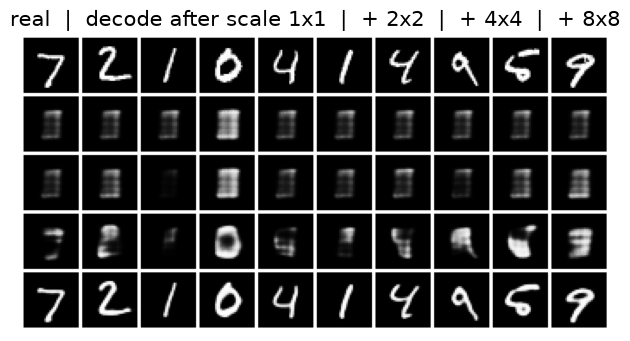

In [23]:
SCALES = (1, 2, 4, 8)
class MSVQ(nn.Module):
    def __init__(self, K=256, D=16, scales=SCALES, beta=0.25):
        super().__init__(); self.K, self.D, self.scales, self.beta = K, D, scales, beta
        self.E = nn.Parameter(torch.zeros(K, D)); self.phi = nn.ModuleList([nn.Conv2d(D, D, 3, padding=1) for _ in scales])
        self.register_buffer("ema", torch.zeros(K)); self.register_buffer("ready", torch.tensor(False))
    def phi_k(self, k, h): return 0.5 * h + 0.5 * self.phi[k](h)
    def up(self, q, H): return q if q.shape[-1] == H else F.interpolate(q, size=(H, H), mode="bicubic", align_corners=False)
    def nearest(self, flat):
        return (flat.pow(2).sum(1, keepdim=True) - 2 * flat @ self.E.t() + self.E.pow(2).sum(1)).argmin(1)
    def forward(self, f):
        B, D, H, _ = f.shape; fd = f.detach(); f_hat = torch.zeros_like(f); loss = 0; idxs = []
        if self.training and not self.ready:
            self.E.data.copy_(fd.movedim(1, -1).reshape(-1, D)[torch.randperm(B * H * H, device=f.device)[:self.K]]); self.ready.fill_(True)
        for k, s in enumerate(self.scales):
            rest = fd - f_hat.detach()
            z = F.interpolate(rest, size=(s, s), mode="area") if s < H else rest
            flat = z.movedim(1, -1).reshape(-1, D); idx = self.nearest(flat); idxs.append(idx.view(B, s, s))
            f_hat = f_hat + self.phi_k(k, self.up(self.E[idx].view(B, s, s, D).movedim(-1, 1), H))
            loss = loss + F.mse_loss(f_hat, fd) + self.beta * F.mse_loss(f_hat.detach(), f)
            if self.training:
                with torch.no_grad(): self.ema.mul_(0.995).add_(0.005 * torch.bincount(idx, minlength=self.K).float())
        if self.training:
            with torch.no_grad():
                dead = self.ema < 0.03 * len(flat) * 85 / 64 / 4 / self.K   # тот же порог, что в разделе 16
                if dead.any():
                    self.E.data[dead] = flat[torch.randint(0, len(flat), (int(dead.sum()),), device=f.device)]; self.ema[dead] = 2.0
        return f + (f_hat - f).detach(), idxs, loss / len(self.scales)
    def accumulate(self, idxs, upto=None, H=8):
        f_hat = 0
        for k, idx in enumerate(idxs[:upto]): f_hat = f_hat + self.phi_k(k, self.up(self.E[idx].movedim(-1, 1), H))
        return f_hat
    def var_inputs(self, idxs, H=8):
        """Вход трансформера для масштаба k+1: накопленная реконструкция после масштабов 1..k, уменьшенная до s_{k+1}."""
        out, f_hat = [], 0
        for k in range(len(self.scales) - 1):
            f_hat = f_hat + self.phi_k(k, self.up(self.E[idxs[k]].movedim(-1, 1), H))
            s = self.scales[k + 1]; out.append(F.interpolate(f_hat, size=(s, s), mode="area") if s < H else f_hat)
        return out

class MSAE(nn.Module):
    def __init__(self):
        super().__init__(); self.q = MSVQ(); self.enc, self.dec = Encoder(4, 16), Decoder(4, 16)
    def forward(self, x):
        fq, idxs, ql = self.q(self.enc(x)); return self.dec(fq), idxs, ql
    @torch.no_grad()
    def encode(self, x): return self.q(self.enc(x.to(DEVICE)))[1]
    @torch.no_grad()
    def decode(self, idxs, upto=None): return self.dec(self.q.accumulate(idxs, upto)).sigmoid()

seed_all(0); ms = MSAE().to(DEVICE); opt = torch.optim.Adam(ms.parameters(), 1e-3)
with Timer() as t:
    for x, _ in batches(Xtr, Ytr, S["bs"], S["steps_vq"], seed=20):
        logits, idxs, ql = ms(x); loss = F.binary_cross_entropy_with_logits(logits, x) + ql
        opt.zero_grad(); loss.backward(); opt.step()
ms.eval()
idx_te = [torch.cat(z).cpu() for z in zip(*[ms.encode(Xte[i:i + 500]) for i in range(0, 2000, 500)])]
rec = torch.cat([ms.decode([z[i:i + 500].to(DEVICE) for z in idx_te]).cpu() for i in range(0, 2000, 500)])
st = code_stats(torch.cat([z.flatten() for z in idx_te]), 256)
f_, p_ = clf_out(rec)
print(f"multi-scale tokenizer: {t.s:.0f} s, 85 tokens/image, PSNR={psnr(rec, Xte[:2000]):.2f} "
      f"(single-scale f=4: {TOK['VQ + restart stats']['psnr']:.2f}), rFD={frechet(f_, F_TE):.2f}, "
      f"rec_acc={(p_.argmax(1) == Yte[:2000]).float().mean():.3f}, usage={st['usage']:.3f}")
show(torch.cat([Xte[:10]] + [ms.decode([z[:10].to(DEVICE) for z in idx_te], upto=u).cpu() for u in [1, 2, 3, 4]]),
     title="real  |  decode after scale 1x1  |  + 2x2  |  + 4x4  |  + 8x8")

Что видно. Декодирование только с масштабами 1×1 и 2×2 даёт почти одинаковое размытое пятно для всех цифр: 5 токенов несут лишь «среднюю» яркость. После 4×4 проступает грубая форма, 8×8 добавляет штрихи. Каждый масштаб уточняет предыдущий, и это делает естественным порядок генерации «от грубого к тонкому». Реконструкция многомасштабного токенизатора по семантике близка к одномасштабному при $f = 4$ (rFD 9,62 против 9,22, точность 0,910 против 0,917), но по PSNR хуже: 24,64 против 27,36 дБ, хотя токенов на 21 больше. Остаточное квантование на нескольких масштабах за то же число шагов обучения сходится медленнее, а грубые масштабы почти не добавляют битов. Зато они дают генератору план изображения.

### 23.2. Трансформер с блочно-причинной маской

Последовательность из 85 позиций разбита на 4 блока по масштабам. Токен масштаба $k$ видит все токены масштабов $1..k$, включая соседей по своему блоку: маска блочно-причинная, а не треугольная. Вход для блока $k+1$ — накопленная реконструкция $\hat f$ после масштабов $1..k$, уменьшенная до $s_{k+1} \times s_{k+1}$. На выходе модель предсказывает сразу все $s_{k+1}^2$ токенов следующего масштаба. Вход первого блока (1 токен) — эмбеддинг класса. Генерация занимает 4 прохода трансформера вместо 64. При генерации маска не нужна: с KV-кэшем на шаге $k$ в сеть подаются только позиции нового масштаба, и они видят весь кэш (более грубые масштабы) и друг друга — ровно то, что разрешает блочная маска.

mask block structure (rows: query level, cols: key level):
[[1 0 0 0]
 [1 1 0 0]
 [1 1 1 0]
 [1 1 1 1]]


encoded train set in 19 s: token maps [(1, 1), (2, 2), (4, 4), (8, 8)]


VAR: 0.84M params, trained 499 s, final train loss 2.430


/tmp/ipykernel_3714/3260384558.py:28: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = linalg.sqrtm(s1 @ s2)


VAR T=1.0      FD=13.73  conf=0.912  div=0.835  acc=0.935  time_s=0.380  (0.4 s for 200 samples, 4 steps)


VAR T=0.8      FD=11.82  conf=0.943  div=0.733  acc=0.975  time_s=0.424  (0.4 s for 200 samples, 4 steps)


VAR top-p=0.95 FD=14.03  conf=0.928  div=0.792  acc=0.945  time_s=0.480  (0.5 s for 200 samples, 4 steps)
code AR T=1.0      FD=12.07  conf=0.829  div=1.089  acc=0.715  time_s=0.581  (64 steps)
code AR T=0.8      FD=10.04  conf=0.848  div=0.977  acc=0.765  time_s=0.553  (64 steps)
code AR top-p=0.95 FD=8.01  conf=0.850  div=0.950  acc=0.760  time_s=0.703  (64 steps)


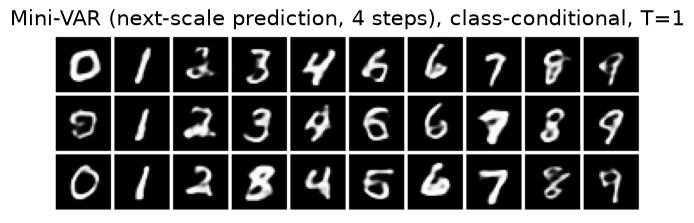

In [24]:
class VARModel(nn.Module):
    def __init__(self, K=256, D=16, scales=SCALES, n_cls=10, d=S["d_ar"], L=4, H=4):
        super().__init__(); self.scales = scales
        lvl = torch.cat([torch.full((s * s,), k) for k, s in enumerate(scales)]); self.N = len(lvl)
        self.register_buffer("lvl", lvl)
        self.register_buffer("mask", torch.where(lvl[None, :] <= lvl[:, None], 0.0, float("-inf")))   # блочно-причинная
        self.cls, self.inp = nn.Embedding(n_cls, d), nn.Linear(D, d)
        self.pos = nn.Parameter(torch.randn(1, self.N, d) * 0.02); self.lvl_emb = nn.Embedding(len(scales), d)
        self.tf, self.head = Transformer(d, H, L), nn.Linear(d, K)
    def embed(self, x, start):                         # позиционный эмбеддинг и эмбеддинг уровня для позиций start..
        T = x.shape[1]; return x + self.pos[:, start:start + T] + self.lvl_emb(self.lvl[start:start + T])
    def forward(self, c, inputs):                      # обучение: все 85 позиций за один проход, маска по блокам
        h = torch.cat([self.cls(c)[:, None]] + [self.inp(x.flatten(2).transpose(1, 2)) for x in inputs], 1)
        T = h.shape[1]; return self.head(self.tf(self.embed(h, 0), mask=self.mask[:T, :T]))

m_ = VARModel(); print("mask block structure (rows: query level, cols: key level):")
print(torch.stack([torch.stack([(m_.mask[m_.lvl == i][:, m_.lvl == j] == 0).float().mean() for j in range(4)]) for i in range(4)]).int().numpy())

with Timer() as t:
    idx_tr = [torch.cat(z).cpu() for z in zip(*[ms.encode(Xtr[i:i + 1000]) for i in range(0, len(Xtr), 1000)])]
print(f"encoded train set in {t.s:.0f} s: token maps {[tuple(z.shape[1:]) for z in idx_tr]}")

seed_all(0); var = VARModel().to(DEVICE)
opt = torch.optim.AdamW(var.parameters(), 1e-3, weight_decay=0.01)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, 1e-3, total_steps=S["steps_var"], pct_start=0.05)
g = torch.Generator().manual_seed(30); var.train()
with Timer() as t:
    for step in range(S["steps_var"]):
        i = torch.randint(0, len(Xtr), (S["bs"],), generator=g)
        idxs = [z[i].to(DEVICE) for z in idx_tr]; c = Ytr[i].to(DEVICE)
        with torch.no_grad(): inputs = ms.q.var_inputs(idxs)
        target = torch.cat([z.flatten(1) for z in idxs], 1)
        loss = F.cross_entropy(var(c, inputs).flatten(0, 1), target.flatten())
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(var.parameters(), 1.0); opt.step(); sched.step()
var.eval()
print(f"VAR: {n_params(var) / 1e6:.2f}M params, trained {t.s:.0f} s, final train loss {loss.item():.3f}")

@torch.no_grad()
def generate_var(c, bs=250, **kw):
    """4 прохода: на шаге k в сеть подаются только s_k^2 новых позиций; KV-кэш хранит предыдущие масштабы, маска не нужна."""
    out = []
    for i in range(0, len(c), bs):
        cb = c[i:i + bs].to(DEVICE); caches = var.tf.new_cache(); h, start, f_hat = var.cls(cb)[:, None], 0, 0
        for k, s in enumerate(SCALES):
            logits = var.head(var.tf(var.embed(h, start), caches=caches))      # B x s^2 x K за один проход
            idx = sample_tokens(logits, **kw).view(-1, s, s)
            f_hat = f_hat + ms.q.phi_k(k, ms.q.up(ms.q.E[idx].movedim(-1, 1), 8)); start += s * s
            if k + 1 < len(SCALES):
                s2 = SCALES[k + 1]; nxt = F.interpolate(f_hat, size=(s2, s2), mode="area") if s2 < 8 else f_hat
                h = var.inp(nxt.flatten(2).transpose(1, 2))
        out.append(ms.dec(f_hat).sigmoid().cpu())
    return torch.cat(out)

VAR_EVAL = {}
for name, kw in [("T=1.0", dict(temperature=1.0)), ("T=0.8", dict(temperature=0.8)), ("top-p=0.95", dict(top_p=0.95))]:
    seed_all(1)
    with Timer() as tv: var_imgs = generate_var(EVAL_LABELS, **kw)
    r = evaluate(var_imgs, EVAL_LABELS); r["time_s"] = tv.s; VAR_EVAL[name] = (r, var_imgs)
    print(f"VAR {name:10s} {fmt(r)}  ({tv.s:.1f} s for {len(var_imgs)} samples, 4 steps)")
for name in ["T=1.0", "T=0.8", "top-p=0.95"]:          # растровый трансформер по кодам, раздел 22
    print(f"code AR {name:10s} {fmt(SW[name][0])}  (64 steps)")
imgs = VAR_EVAL["T=1.0"][1]; k = S["n_eval"] // 10
show(torch.cat([imgs[c * k:c * k + 3] for c in range(10)]).view(10, 3, 1, 32, 32).transpose(0, 1).reshape(30, 1, 32, 32),
     title="Mini-VAR (next-scale prediction, 4 steps), class-conditional, T=1")

Что видно. Блочная маска — нижнетреугольная матрица из единиц на уровне блоков: масштаб видит себя и все более грубые масштабы. Мини-VAR генерирует цифры за 4 прохода трансформера и 0,4 с на 200 образцов против 64 проходов и 0,6 с у растрового трансформера по кодам. Выигрыш по времени меньше, чем по числу шагов: с KV-кэшем каждый проход обрабатывает только новые позиции (1, 4, 16 и 64), и последний проход по 64 позициям — самый дорогой. Условие на класс у мини-VAR соблюдается заметно лучше: точность 0,935 против 0,715 при $T = 1$, уверенность 0,912 против 0,829. FD сопоставим (13,73 против 12,07), но разнообразие ниже (0,835 против 1,089). Внутри одного масштаба токены сэмплируются независимо при условии предыдущих масштабов, поэтому соседние токены могут «не договориться» между собой. Это главный компромисс параллельной генерации: чем больше токенов выбирается за шаг, тем сильнее предположение об их условной независимости. VAR компенсирует его большим числом масштабов (10 для 256×256) и размером модели; у нас масштабов 4, а модель крошечная. Top-p 0,95 для мини-VAR не помог (FD 14,03), а $T = 0{,}8$ немного улучшил FD (11,82) ценой разнообразия.

## 24. Сводка: генеративная трилемма в цифрах

Соберём все генераторы практикума в одну таблицу. Число проходов сети на изображение и время генерации — скорость. FD и уверенность классификатора — качество. Разнообразие — покрытие мод. Время генерации включает декодирование токенов в пиксели.

In [25]:
rows = [("real test sample", "-", base_real),
        ("VAE beta=1 (prior samples)", 1, {**{k: VAES["r1.0"][k] for k in ["FD", "conf", "div"]}}),
        ("pixel AR, 16x16 palette", 256, PIX_EVAL),
        ("code AR (VQ f=4), T=1", 64, AR_EVAL),
        ("code AR, top-p=0.95", 64, SW["top-p=0.95"][0]),
        ("mini-VAR, T=1", 4, VAR_EVAL["T=1.0"][0]),
        ("mini-VAR, top-p=0.95", 4, VAR_EVAL["top-p=0.95"][0])]
with Timer() as tvae: VAES[1.0].sample(S["n_eval"])
times = {"VAE beta=1 (prior samples)": tvae.s}
print(f"{'model':28s} {'passes':>6} {'gen s':>6} {'FD':>7} {'conf':>6} {'div':>6} {'acc':>6}")
for name, passes, r in rows:
    ts = times.get(name, r.get("time_s"))
    gen_s = f"{ts:.1f}" if ts is not None else "-"
    acc = f"{r['acc']:.3f}" if "acc" in r else "-"
    print(f"{name:28s} {passes:>6} {gen_s:>6} {r['FD']:>7.2f} {r['conf']:>6.3f} {r['div']:>6.3f} {acc:>6}")
print(f"\nn_eval={S['n_eval']} samples per model; FAST_DEV_RUN={FAST_DEV_RUN}; device={DEVICE}")

model                        passes  gen s      FD   conf    div    acc
real test sample                  -      -    3.07  0.928  1.000  0.930
VAE beta=1 (prior samples)        1    0.0  117.17  0.635  0.805      -
pixel AR, 16x16 palette         256    2.8  204.03  0.773  1.239      -
code AR (VQ f=4), T=1            64    0.6   12.07  0.829  1.089  0.715
code AR, top-p=0.95              64    0.7    8.01  0.850  0.950  0.760
mini-VAR, T=1                     4    0.4   13.73  0.912  0.835  0.935
mini-VAR, top-p=0.95              4    0.5   14.03  0.928  0.792  0.945

n_eval=200 samples per model; FAST_DEV_RUN=True; device=cpu


Что видно. VAE быстрее всех (один проход декодера), но его образцы размыты: FD = 117. Пиксельный авторегрессор даёт лучшее правдоподобие из простых моделей, но тратит 256 проходов на изображение 16×16, а его образцы в этом прогоне хуже всех (FD = 204). Трансформер по кодам VQ получает FD = 12,07 за 64 прохода, с top-p 0,95 — 8,01: токенизатор взял на себя локальные детали, а приор — глобальную структуру. Мини-VAR сокращает число проходов до 4 при сопоставимом FD (13,73) и лучшем соблюдении класса (0,935), но с меньшим разнообразием (0,835 против 1,089). Ни одна модель не выигрывает по всем трём осям сразу — это генеративная трилемма в миниатюре. Абсолютные числа зависят от длительности обучения: на CPU модели недообучены, и на GPU с большим числом шагов соотношение между приорами по качеству может измениться. Устойчивы выводы о числе проходов и о том, что потолок качества задаёт токенизатор: FD образцов поверх VQ не опускается ниже FD его реконструкций (7,40).

# Выводы

1. Генеративная модель задаёт распределение $p_\theta(x)$. Правдоподобие (bits/dim), качество образцов и скорость сэмплинга — разные оси, и ни одно семейство моделей не выигрывает по всем трём (генеративная трилемма). В практикуме пиксельный авторегрессор снизил bits/dim с 0,844 до 0,669 относительно независимых пикселей, а его образцы оказались хуже, чем у VAE (FD 204 против 117).
2. VAE даёт непрерывный латент и мгновенную генерацию, но гауссов декодер усредняет, а рост $\beta$ отключает координаты латента (42 активных из 64 при $\beta = 1$, 16 при $\beta = 4$).
3. VQ-VAE заменяет гауссов латент дискретными кодами. Ключевые детали — codebook и commitment loss со stop-gradient, straight-through estimator и борьба с коллапсом кодов. Без перезапуска наивный VQ использовал 24,6% кодов (перплексия 38 из 256), с перезапуском — 99,6%; FSQ использует всю решётку без вспомогательных потерь.
4. Степень сжатия $f$ задаёт длину последовательности $N = HW/f^2$ и rate $N \log_2 K$. Короче последовательность — дешевле приор, но ниже потолок реконструкции: при переходе от $f = 4$ к $f = 8$ PSNR упал с 27,4 до 22,6 дБ, rFD вырос с 9,2 до 35,7.
5. VQGAN держит качество при сильном сжатии за счёт перцептивной и adversarial-потерь с адаптивным весом. У нас при $f = 8$ rFD упал с 35,7 до 4,9 при почти неизменном PSNR.
6. Современные системы используют 256–1024 (иногда 4096) дискретных токенов со словарём $10^4$–$10^5$ для генерации и непрерывные ViT-признаки для понимания. Janus разделяет эти два кодировщика.
7. Авторегрессия по токенам переносит задачу на язык LLM: кросс-энтропия, KV-кэш, classifier-free guidance. Трансформер по кодам дал FD 12,1 за 64 шага против 204 за 256 шагов у пиксельной модели.
8. VAR меняет единицу авторегрессии на масштаб: $O(\log n)$ шагов вместо $O(n^2)$. Мини-VAR сгенерировал цифры за 4 прохода с сопоставимым FD (13,7) и лучшей точностью класса (0,935 против 0,715), но с меньшим разнообразием.
9. Temperature, top-k и top-p — гиперпараметры, которые двигают модель вдоль кривой «качество — разнообразие». Их подбирают по метрикам на валидации. В нашем прогоне greedy дал 10 уникальных изображений из 200, а лучший FD — $T = 0{,}5$.
10. Все числа практикума получены на CPU в режиме `FAST_DEV_RUN` на 200 образцах. GPU-ветка блокнота не проверялась, и на ней значения будут другими; переносить стоит направления эффектов, а не цифры.

# Контрольные вопросы

1. Модель тратит в среднем 2,5 бита на измерение для изображений 32×32×3. Сколько это бит и килобайт на изображение? Ответ: $2{,}5 \cdot 3072 = 7680$ бит, 960 байт.
2. Почему правдоподобие нельзя напрямую сравнивать у модели на пикселях и модели на индексах VQ? Что именно измеряет bpd в каждом случае?
3. Сформулируйте генеративную трилемму. Где в ней VAE, GAN, диффузия, AR на токенах и VAR?
4. Запишите ELBO. Какое слагаемое отвечает за «rate», какое за «distortion»? Что происходит при $\beta = 4$?
5. Что такое posterior collapse? Почему VQ-VAE ему не подвержен?
6. Запишите функцию потерь VQ-VAE. Зачем нужен stop-gradient в каждом из двух вспомогательных слагаемых? Что будет, если $\beta = 0$?
7. Как работает straight-through estimator? Запишите его одной строкой кода на PyTorch.
8. Опишите механизм коллапса кодов как положительную обратную связь. Почему он усиливается с ростом размерности кодов?
9. Codebook из 1024 кодов имеет перплексию 64. Сколько бит на токен реально используется? Ответ: $\log_2 64 = 6$ бит вместо 10.
10. Сравните перезапуск мёртвых кодов, нормированные низкоразмерные коды, FSQ и LFQ. Какой из них не имеет обучаемого codebook?
11. FSQ с уровнями [8, 5, 5, 5]: каков неявный размер словаря и бит на токен? Ответ: 1000 кодов, около 9,97 бита.
12. Зачем в VQGAN адаптивный вес $\lambda$? Почему градиенты берутся именно на последнем слое декодера?
13. Изображение 512×512, $f = 16$, $K = 16\,384$. Найдите $N$ и rate. Ответ: $32 \cdot 32 = 1024$ токена, $1024 \cdot 14 = 14\,336$ бит.
14. Во сколько раз вырастет стоимость self-attention при переходе от $f = 16$ к $f = 8$ на том же изображении? Ответ: $N$ растёт в 4 раза, внимание — в 16 раз.
15. Почему Janus использует разные энкодеры для понимания и генерации?
16. Опишите двухэтапную схему «токенизатор + AR-приор». Что замораживается и когда?
17. Запишите формулу CFG для логитов. Что нужно сделать при обучении, чтобы CFG был возможен?
18. Масштабы VAR 1, 2, 3, 4, 5, 6, 8, 10, 13, 16. Сколько всего токенов и сколько последовательных шагов? Сравните с растровой AR на сетке 16×16. Ответ: 680 токенов за 10 шагов против 256 шагов.
19. Что видит токен масштаба $k$ при обучении VAR? Зачем на инференсе маска не нужна?
20. Распределение $p = (0{,}5;\ 0{,}2;\ 0{,}15;\ 0{,}1;\ 0{,}05)$. Какие токены останутся при top-p = 0,8 и какие у них будут вероятности? Ответ: первые три (0,85 ≥ 0,8): $0{,}588;\ 0{,}235;\ 0{,}176$.
21. Почему greedy-декодирование вырождается для изображений?
22. Чем rFID отличается от gFID? Может ли токенизатор с лучшим rFID дать худший gFID?

# Задания

1. Коллапс кодов. Обучите VQ из раздела 16 с $K = 256$ и $K = 1024$ без перезапуска и с перезапуском. Постройте usage и perplexity по шагам обучения. При каком $K$ перезапуск становится необходим?
2. Commitment loss. Повторите обучение VQ+restart с $\beta \in \{0;\ 0{,}05;\ 0{,}25;\ 1;\ 2\}$. Как меняются PSNR, норма выходов энкодера и usage?
3. FSQ против VQ. Подберите уровни FSQ с неявным словарём около 512 и 4096. Сравните с VQ того же размера по PSNR, rFD и usage.
4. Сжатие. Добавьте $f = 16$ (сетка 2×2) к таблице раздела 17. Где кончается полезная реконструкция для MNIST 32×32?
5. Сэмплинг. Для AR на кодах постройте кривую «FD — разнообразие» по сетке $T \in [0{,}5;\ 1{,}5]$ и $p \in [0{,}7;\ 1]$. Найдите парето-оптимальные настройки.
6. CFG. Добавьте в AR на кодах замену класса на пустой токен с вероятностью 0,1 и реализуйте guidance по формуле раздела 10.3. Как меняются точность классификатора и разнообразие при $s \in \{1;\ 1{,}5;\ 2;\ 3\}$?
7. VAR. Замените масштабы (1, 2, 4, 8) на (1, 2, 3, 4, 6, 8). Как меняются число токенов, время генерации и качество?
8. Порядок генерации. Обучите AR на кодах с порядком «змейка» или со случайной перестановкой позиций (с позиционными эмбеддингами исходной сетки). Сравните валидационную кросс-энтропию с растровым порядком.

# Источники

1. Kingma D. P., Welling M. Auto-Encoding Variational Bayes, 2013. https://arxiv.org/abs/1312.6114
2. Higgins I. et al. β-VAE: Learning Basic Visual Concepts with a Constrained Variational Framework, ICLR 2017. https://openreview.net/forum?id=Sy2fzU9gl
3. Bowman S. R. et al. Generating Sentences from a Continuous Space, 2016. https://arxiv.org/abs/1511.06349
4. van den Oord A., Vinyals O., Kavukcuoglu K. Neural Discrete Representation Learning (VQ-VAE), 2017. https://arxiv.org/abs/1711.00937
5. Razavi A., van den Oord A., Vinyals O. Generating Diverse High-Fidelity Images with VQ-VAE-2, 2019. https://arxiv.org/abs/1906.00446
6. Esser P., Rombach R., Ommer B. Taming Transformers for High-Resolution Image Synthesis (VQGAN), 2021. https://arxiv.org/abs/2012.09841
7. Yu J. et al. Vector-quantized Image Modeling with Improved VQGAN (ViT-VQGAN), 2021. https://arxiv.org/pdf/2110.04627
8. Mentzer F. et al. Finite Scalar Quantization: VQ-VAE Made Simple, 2023. https://arxiv.org/abs/2309.15505
9. Yu L. et al. Language Model Beats Diffusion: Tokenizer is Key to Visual Generation (MAGVIT-v2, LFQ), 2023. https://arxiv.org/pdf/2310.05737
10. Fifty C. et al. Restructuring Vector Quantization with the Rotation Trick, 2024. https://arxiv.org/abs/2410.06424
11. Dhariwal P. et al. Jukebox: A Generative Model for Music, 2020. https://arxiv.org/pdf/2005.00341
12. Xiao Z., Kreis K., Vahdat A. Tackling the Generative Learning Trilemma with Denoising Diffusion GANs, 2021. https://arxiv.org/abs/2112.07804
13. Salimans T. et al. PixelCNN++, 2017. https://arxiv.org/abs/1701.05517
14. Ho J., Jain A., Abbeel P. Denoising Diffusion Probabilistic Models, 2020. https://arxiv.org/abs/2006.11239
15. van den Oord A., Kalchbrenner N., Kavukcuoglu K. Pixel Recurrent Neural Networks, 2016. https://arxiv.org/abs/1601.06759
16. van den Oord A. et al. Conditional Image Generation with PixelCNN Decoders, 2016. https://arxiv.org/abs/1606.05328
17. Chen M. et al. Generative Pretraining from Pixels (ImageGPT), 2020. https://cdn.openai.com/papers/Generative_Pretraining_from_Pixels_V2.pdf
18. Ramesh A. et al. Zero-Shot Text-to-Image Generation (DALL-E), 2021. https://arxiv.org/pdf/2102.12092v2
19. Yu J. et al. Scaling Autoregressive Models for Content-Rich Text-to-Image Generation (Parti), 2022. https://arxiv.org/abs/2206.10789
20. Chang H. et al. MaskGIT: Masked Generative Image Transformer, 2022. https://arxiv.org/pdf/2202.04200
21. Sun P. et al. Autoregressive Model Beats Diffusion: Llama for Scalable Image Generation (LlamaGen), 2024. https://arxiv.org/html/2406.06525
22. Tian K. et al. Visual Autoregressive Modeling: Scalable Image Generation via Next-Scale Prediction (VAR), 2024. https://arxiv.org/abs/2404.02905 ; код: https://github.com/FoundationVision/VAR
23. Yu Q. et al. An Image is Worth 32 Tokens for Reconstruction and Generation (TiTok), 2024. https://arxiv.org/abs/2406.07550
24. Rombach R. et al. High-Resolution Image Synthesis with Latent Diffusion Models, 2022. https://arxiv.org/pdf/2112.10752
25. Chameleon Team. Chameleon: Mixed-Modal Early-Fusion Foundation Models, 2024. https://arxiv.org/pdf/2405.09818
26. Wang X. et al. Emu3: Next-Token Prediction is All You Need, 2024. https://arxiv.org/html/2409.18869
27. Wu C. et al. Janus: Decoupling Visual Encoding for Unified Multimodal Understanding and Generation, 2024. https://arxiv.org/pdf/2410.13848
28. Wang P. et al. Qwen2-VL, 2024. https://arxiv.org/html/2409.12191
29. Ho J., Salimans T. Classifier-Free Diffusion Guidance, 2022. https://arxiv.org/abs/2207.12598
30. Holtzman A. et al. The Curious Case of Neural Text Degeneration (top-p), 2019. https://arxiv.org/abs/1904.09751
31. Fan A., Lewis M., Dauphin Y. Hierarchical Neural Story Generation (top-k), 2018. https://arxiv.org/abs/1805.04833
32. Heusel M. et al. GANs Trained by a Two Time-Scale Update Rule Converge to a Local Nash Equilibrium (FID), 2017. https://arxiv.org/abs/1706.08500
33. Kynkäänniemi T. et al. Improved Precision and Recall Metric for Assessing Generative Models, 2019. https://arxiv.org/abs/1904.06991
34. Theis L., van den Oord A., Bethge M. A Note on the Evaluation of Generative Models, 2016. https://arxiv.org/abs/1511.01844
35. LeCun Y., Cortes C., Burges C. MNIST database. https://yann.lecun.org/exdb/mnist/index.html
36. Bohan O. B. TAESD: Tiny AutoEncoder for Stable Diffusion. https://huggingface.co/madebyollin/taesd
37. Изображение для раздела 19: COCO val2017, 000000039769. http://images.cocodataset.org/val2017/000000039769.jpg